# Инженерия признаков: прогнозирование покупки на сайте e-commerce

**Дисциплина:** Машинное обучение и ИИ
**Модуль 4:** Инженерия признаков и работа с нестандартными данными
**Датасет:** Online Shoppers Purchasing Intention

**Выполнил:** Бреславская Ирина
**Группа:** ПКТб-23-1
**Преподаватель:** Спирин Игорь Сергеевич

**Ссылка на репозиторий:** https://github.com/breslavskayaira/ml-course-breslavskaya
**Путь к модулю:** `module-4-features/notebook.ipynb`
**Дата сдачи:** 2026-11-01

## Введение

1. **Какую задачу решаем?**
   Мы решаем задачу бинарной классификации в сфере электронной коммерции (e-commerce) — прогнозирование намерения пользователя совершить покупку во время текущей веб-сессии (`Revenue`: `True / 1` — сессия завершилась покупкой, `False / 0` — пользователь покинул сайт без покупки) на основе поведенческих, технических и временных характеристик визита.

2. **Что такое инженерия признаков (Feature Engineering)?**
   Инженерия признаков — это процесс трансформации «сырых» данных и создания новых информативных признаков на основе существующих с использованием знаний о предметной области для повышения точности моделей машинного обучения. Как гласит фундаментальный принцип ML: *«Признаки важнее алгоритмов: хорошие признаки с простой моделью дают лучший результат, чем плохие признаки со сложной моделью»*.

3. **Почему для IT-компании важно прогнозировать покупку?**
   Для интернет-магазинов и маркетплейсов прогнозирование конверсии в реальном времени имеет прямую бизнес-ценность:
   - Позволяет динамически таргетировать «сомневающейся» сегмент пользователей (показывать персональный промокод, всплывающий виджет помощи или бесплатную доставку только тем, кто близок к покупке, но рискует уйти).
   - Оптимизирует расходы на ретаргетинг и рекламный трафик.
   - Помогает выявлять узкие места в UX/UI воронки продаж (страницы с высоким показателем отказов `BounceRates` и выходов `ExitRates`).

4. **Какая метрика важнее в этой задаче?**
   В датасете наблюдается **сильный дисбаланс классов**: `84.5%` сессий завершаются без покупки (`10 422`), и только `15.5%` приводят к транзакции (`1 908`). Поэтому метрика `Accuracy` неинформативна: константный классификатор, всегда предсказывающий `False`, получит `Accuracy = 84.5%`, но пропустит 100% покупателей. Ключевыми метриками являются:
   - **ROC-AUC** — интегральная метрика качества ранжирования вероятностей покупки, инвариантная к дисбалансу классов.
   - **F1-score**, **Precision** и **Recall** — позволяют контролировать баланс между полнотой охвата потенциальных покупателей (`Recall`) и точностью таргетинга (`Precision`), чтобы не раздавать маркетинговые скидки впустую.

5. **Цель работы:**
   - Создать 5+ новых признаков на основе поведения пользователя (суммарные, средние, относительные, временные и интерактивные метрики).
   - Обучить 4 ансамблевые модели (`Random Forest`, `XGBoost`, `LightGBM`, `CatBoost`) и сравнить их по качеству и скорости обучения.
   - Оптимизировать лучшую модель через `Optuna` и интерпретировать влияние созданных признаков через `SHAP`.

## Теоретическая часть

### 1. Инженерия признаков (Feature Engineering) и работа с нестандартными данными
**Feature Engineering** — это комплекс методов извлечения скрытой информации из исходных данных, повышения нелинейности (полиномы, логарифмирование скошенных распределений), снижения размерности и перевода нестандартных данных в табличный числовой вид. В современных IT-системах сырые данные редко представляют собой готовую числовую матрицу — они включают логи сессий, тексты, геокоординаты и временные метки:

| Тип данных | Методы обработки и конструирования признаков | Инструменты Python |
|---|---|---|
| **Числовые** | Масштабирование, биннинг, логарифмирование, отношения и суммы | `StandardScaler`, `pd.cut()`, `np.log1p()`, `PolynomialFeatures` |
| **Категориальные** | Label Encoding, One-Hot Encoding, Target Encoding, Frequency Encoding | `LabelEncoder`, `OneHotEncoder`, `pd.get_dummies()` |
| **Текстовые (NLP)** | Мешок слов (Bag of Words), взвешивание TF-IDF, n-граммы, эмбеддинги | `CountVectorizer`, `TfidfVectorizer`, `BERT / Word2Vec` |
| **Геопространственные** | Сферическое расстояние Хаверсина, плотностная кластеризация DBSCAN | `np.radians()`, `DBSCAN(eps, min_samples)` |
| **Временные ряды** | Извлечение частей даты, лаги (сдвиги), скользящие окна, первые разности | `dt.month`, `dt.dayofweek`, `shift()`, `rolling()`, `diff()` |

**Математический аппарат обработки нестандартных данных (из теории Модуля 4):**
- **Текстовые признаки (TF-IDF):** оценивают важность слова $t$ в документе $d$ корпуса объёма $N$ пропорционально частоте слова в документе $\text{TF}(t, d)$ и обратно пропорционально числу документов $\text{DF}(t)$, где оно встречается:
$$\text{TFIDF}(t, d) = \text{TF}(t, d) \times \text{IDF}(t), \quad \text{IDF}(t) = \log\left(\frac{N}{\text{DF}(t)}\right)$$
- **Геопространственные признаки (формула Хаверсина и DBSCAN):** так как Земля имеет сферическую форму (радиус $R \approx 6371\text{ км}$), евклидова разность координат широты $\phi$ и долготы $\lambda$ физически некорректна. Расстояние вычисляется по формуле Хаверсина:
$$a = \sin^2\left(\frac{\Delta\phi}{2}\right) + \cos(\phi_1)\cos(\phi_2)\sin^2\left(\frac{\Delta\lambda}{2}\right), \quad d = 2R \cdot \text{atan2}\left(\sqrt{a}, \sqrt{1-a}\right)$$
Для выделения пространственных кластеров и поиска гео-аномалий (метка `-1`) без задания числа кластеров применяется алгоритм **DBSCAN** с параметрами радиуса окрестности `eps` и минимального числа соседей `min_samples`.

### 2. Категориальные признаки: Label Encoding vs One-Hot Encoding vs Target Encoding
- **Label Encoding** заменяет каждую категорию целым числом от $0$ до $K-1$. Он компактен и хорошо подходит для древовидных моделей при малой кардинальности, но создаёт искусственный числовой порядок ($0 < 1 < 2$), который может искажать линейные и метрические алгоритмы.
- **One-Hot Encoding (OHE)** создаёт бинарный столбец-индикатор ($0/1$) для каждого уникального значения категории, устраняя ложный порядок, но при большом числе категорий приводит к «проклятию размерности» и разреженности матрицы.
- **Target Encoding** заменяет категорию средним значением целевой переменной по этой категории (с использованием кросс-валидации или сглаживания для предотвращения утечки целевой переменной *Data Leakage*).

### 3. Временные признаки и динамика рядов
Из временных отметок извлекаются календарные компоненты (`MonthNum`, `DayOfWeek`, индикатор выходного дня `IsWeekend`, близость к праздникам `SpecialDay`), которые позволяют модели улавливать недельную и годовую сезонность покупательской активности. В последовательных временных рядах ключевую роль играют **лаги** (`shift(k)` — учёт автокорреляции с прошлыми шагами), **скользящие окна** (`rolling(w).mean()` / `.std()` — сглаживание шума и оценка локального тренда) и **разности** (`diff()` — скорость изменения показателя).

### 4. Создание признаков на основе поведения пользователя (Behavioral Feature Engineering)
В аналитике электронной коммерции отдельные счётчики посещённых страниц (`Administrative`, `Informational`, `ProductRelated`) и времени на них дают разрозненную картину. Конструирование агрегированных поведенческих признаков позволяет явно выделить глубину вовлечённости пользователя:
- **Суммарные метрики:** общее число просмотренных страниц `TotalPages` и общая длительность сессии `TotalDuration` отражают масштаб интереса к сайту.
- **Средние и удельные показатели:** удельная ценность просмотра `AvgPageValue = PageValues / (TotalPages + 1)` и среднее время на страницу `AvgDurationPerPage` отделяют вдумчивое изучение товара от случайного прокликивания.
- **Отношения и взаимодействия:** отношение отказов к выходам `BounceExitRatio = BounceRates / (ExitRates + 0.001)` и доля товарных страниц `ProductPageShare` характеризуют структуру навигации клиента.

**Схема конструирования признаков в проекте:**
```text
Сырые данные сессии (17 признаков)
  ├──► Счётчики и время (Admin, Info, Product) ──► Суммы и доли: TotalPages, TotalDuration, ProductPageShare
  ├──► Метрики Google Analytics (Bounce, Exit, PageValues) ──► Отношения: AvgPageValue, BounceExitRatio, EngagementScore
  ├──► Категории (VisitorType, TrafficType) ──► Индикаторы и Target Encoding: IsNewVisitor, IsHighTraffic
  └──► Календарь (Month, Weekend, SpecialDay) ──► Временные: MonthNum, IsWeekend, Q4_Season
```

### 5. Дисбаланс классов и методы борьбы с ним
При соотношении классов `84.5%` к `15.5%` стандартная функция потерь уделяет основное внимание классу большинства, игнорируя редкие покупки. Для решения проблемы применяются:
- **Алгоритмическая балансировка весов (`class_weight='balanced'`, `scale_pos_weight`):** штраф за ошибку на объекте миноритарного класса увеличивается пропорционально отношению частот классов $N_{\text{neg}} / N_{\text{pos}} \approx 5.46$.
- **Сэмплирование (`SMOTE` — Synthetic Minority Over-sampling Technique):** синтетическая генерация новых примеров положительного класса путём интерполяции между ближайшими соседями в пространстве признаков.

### 6. Ансамблевые модели и интерпретация через SHAP
Для обучения на сконструированных признаках используются ансамбли деревьев, объединяющие базовые модели $h_i(x)$ параллельно с усреднением (**Bagging**: $H(x) = \frac{1}{M}\sum_{i=1}^M h_i(x)$, снижает *Variance*) или последовательно с весами (**Boosting**: $H(x) = \sum_{i=1}^M \alpha_i h_i(x)$, снижает *Bias*):

| Критерий | Random Forest | XGBoost | LightGBM | CatBoost |
|---|---|---|---|---|
| **Тип ансамбля** | Bagging | Gradient Boosting | Gradient Boosting | Gradient Boosting |
| **Архитектура дерева** | Глубокие независимые деревья | Level-wise (по уровням) | Leaf-wise (по лучшему листу) | Симметричные деревья (Oblivious) |
| **Скорость обучения** | Средняя | Средняя | **Высокая** (гистограммы + GOSS) | Умеренная |
| **Работа с категориями** | Требует кодирования | Требует кодирования | Оптимизированный биннинг | **Автоматический Target Encoding** |
| **Борьба с дисбалансом** | `class_weight='balanced'` | `scale_pos_weight` | `class_weight='balanced'` | `auto_class_weights='Balanced'` |

Для объяснения вклада каждого созданного признака в прогноз модели применяется метод **SHAP (SHapley Additive exPlanations)**, основанный на значениях Шепли из теории кооперативных игр:
$$\phi_i = \sum_{S \subseteq N \setminus \{i\}} \frac{|S|!(|N| - |S| - 1)!}{|N|!} [v(S \cup \{i\}) - v(S)]$$
Графики `Summary plot` (глобальная важность и направление влияния), `Waterfall plot` (разбор конкретного покупателя) и `Dependence plot` (нелинейная зависимость вклада признака от его значения) позволяют верифицировать пользу новых признаков.

## Описание данных

**Источник:** https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention (UCI Machine Learning Repository: *Online Shoppers Purchasing Intention Dataset*, авторы C. O. Sakar et al., 2018)

**Структура:**
- Всего примеров (сессий): `12 330`
- Признаков: `17` входных (+ целевая переменная `Revenue`, всего 18 столбцов)
- Числовых признаков: `10` (`Administrative`, `Administrative_Duration`, `Informational`, `Informational_Duration`, `ProductRelated`, `ProductRelated_Duration`, `BounceRates`, `ExitRates`, `PageValues`, `SpecialDay`)
- Категориальных и булевых признаков: `7` (`Month`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `VisitorType`, `Weekend`)

**Описание ключевых столбцов:**

| Столбец | Тип | Описание | Пропуски |
|---|---|---|---|
| `Administrative` | int64 | Число посещённых административных страниц за сессию | 0% |
| `Administrative_Duration` | float64 | Общее время на административных страницах (сек) | 0% |
| `Informational` | int64 | Число посещённых информационных страниц | 0% |
| `Informational_Duration` | float64 | Общее время на информационных страницах (сек) | 0% |
| `ProductRelated` | int64 | Число посещённых товарных страниц | 0% |
| `ProductRelated_Duration` | float64 | Общее время на товарных страницах (сек) | 0% |
| `BounceRates` | float64 | Средний показатель отказов просмотренных страниц | 0% |
| `ExitRates` | float64 | Средний показатель выходов со страниц сессии | 0% |
| `PageValues` | float64 | Средняя ценность страницы перед транзакцией (Google Analytics) | 0% |
| `SpecialDay` | float64 | Близость даты визита к празднику (от 0 до 1.0) | 0% |
| `Month` | object | Месяц сессии (`Feb`, `Mar`, `May`, ..., `Nov`, `Dec`) | 0% |
| `VisitorType` | object | Тип посетителя (`Returning_Visitor`, `New_Visitor`, `Other`) | 0% |
| `Weekend` | bool | Признак посещения в выходной день (`True` / `False`) | 0% |
| `Revenue` | bool | **Целевая переменная** (`True` — покупка совершена, `False` — нет) | 0% |

**Распределение классов:**
- `False` (нет покупки): `10 422` сессии (`84.53%`)
- `True` (покупка): `1 908` сессий (`15.47%`)

**Файл описания данных в репозитории:** `module-4-features/data/dataset_info.md`

In [1]:
# ============================================================
# РАЗДЕЛ 4: ИМПОРТ БИБЛИОТЕК, ЗАГРУЗКА И ОПИСАНИЕ ДАННЫХ
# ============================================================

import os
import json
import time
import warnings
from io import BytesIO

import numpy as np
# NumPy — быстрые векторизованные операции над массивами и математические функции.

import pandas as pd
# Pandas — загрузка табличных данных, агрегация и конструирование новых признаков.

import matplotlib.pyplot as plt
import seaborn as sns
# Matplotlib и Seaborn — построение аналитических графиков EDA, матриц ошибок и ROC-кривых.

import joblib
import requests
# joblib и requests — сериализация моделей в .pkl и проверка загрузки из GitHub.

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
# Инструменты валидации: стратифицированное разбиение и кросс-валидация с сохранением пропорции классов.

from sklearn.preprocessing import LabelEncoder, StandardScaler
# Кодирование категориальных признаков и стандартизация числовых шкал.

from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
# Случайный лес (Bagging) и калибровка вероятностей для бонусной части.

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
# Градиентные бустинги: XGBoost, LightGBM и CatBoost.

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, roc_curve
)
# Метрики качества бинарной классификации.

import optuna
import shap
# Optuna — байесовский поиск гиперпараметров; SHAP — интерпретация моделей через значения Шепли.

warnings.filterwarnings('ignore')
# Отключаем предупреждения для аккуратного отображения отчёта.

# Создаём структуру папок модуля внутри репозитория
os.makedirs('data', exist_ok=True)
os.makedirs('models', exist_ok=True)
os.makedirs('examples', exist_ok=True)

# Относительный путь к датасету согласно требованиям задания
data_path = 'data/online_shoppers_intention.csv'

# Если файл ещё не скачан локально, автоматически загружаем его из официального зеркала UCI
if not os.path.exists(data_path):
    uci_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv"
    df_loaded = pd.read_csv(uci_url)
    df_loaded.to_csv(data_path, index=False)

# Чтение датасета
df = pd.read_csv(data_path)

# Автоматическое создание файла описания data/dataset_info.md
dataset_info_content = """# Online Shoppers Purchasing Intention Dataset
- **Источник:** https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention (UCI ID: 468)
- **Всего записей:** 12 330 сессий
- **Признаков:** 17 входных + целевая переменная Revenue
- **Распределение классов:** False = 10 422 (84.53%), True = 1 908 (15.47%)
"""
with open('data/dataset_info.md', 'w', encoding='utf-8') as f:
    f.write(dataset_info_content)

# Обязательный вывод размерности и первых 5 строк датасета
print("=" * 65)
print("РАЗМЕРНОСТЬ ДАТАСЕТА (df.shape):")
print("=" * 65)
print(df.shape)

print("\n" + "=" * 65)
print("ПЕРВЫЕ 5 СТРОК ДАТАСЕТА (df.head()):")
print("=" * 65)
print(df.head())

print("\n" + "=" * 65)
print("РАСПРЕДЕЛЕНИЕ КЛАССОВ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ (Revenue):")
print("=" * 65)
print(df['Revenue'].value_counts())
print("\nДоля каждого класса (%):")
print((df['Revenue'].value_counts(normalize=True) * 100).round(2))

РАЗМЕРНОСТЬ ДАТАСЕТА (df.shape):
(12330, 18)

ПЕРВЫЕ 5 СТРОК ДАТАСЕТА (df.head()):
   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  \
0         0.20       0.20         0.0         0.0   

**Выводы по разделу 4:**
- Датасет `Online Shoppers Purchasing Intention` загружен из `data/online_shoppers_intention.csv` и содержит `12 330` строк (пользовательских сессий) и `18` столбцов.
- Сформирован файл описания `data/dataset_info.md`.
- Выявлен сильный дисбаланс целевого признака `Revenue`: `84.53%` сессий без покупки (`10 422`) и `15.47%` сессий с покупкой (`1 908`), что делает обязательным применение стратификации (`stratify=y`) и взвешивания классов (`class_weight='balanced'`, `scale_pos_weight ≈ 5.46`).

## Подготовка данных и EDA

Выполним первичный осмотр типов данных и описательных статистик, проверим отсутствие пропусков, сконструируем **10 новых признаков** на основе поведения пользователя и календарных факторов (*Feature Engineering*), построим 6 графиков разведочного анализа данных (EDA), закодируем категориальные переменные и разделим данные на `train` и `test` со стратификацией.

### Обоснование создаваемых признаков (Feature Engineering):
1. **`TotalPages`** (`Administrative + Informational + ProductRelated`) — суммарная глубина просмотра сайта за сессию; отражает общую вовлечённость посетителя.
2. **`TotalDuration`** (`Administrative_Duration + Informational_Duration + ProductRelated_Duration`) — общее время (в секундах), проведённое пользователем на сайте за визит.
3. **`AvgPageValue`** (`PageValues / (TotalPages + 1)`) — удельная конверсионная ценность одного просмотренного экрана; позволяет отличить целенаправленный выбор товара от бесцельного серфинга.
4. **`BounceExitRatio`** (`BounceRates / (ExitRates + 0.001)`) — отношение скорости мгновенных отказов к общей частоте выходов со страниц; выделяет сессии, где пользователь сразу сталкивается с нерелевантным контентом.
5. **`IsNewVisitor`** (`(VisitorType == 'New_Visitor').astype(int)`) — бинарный индикатор нового посетителя, так как поведенческие паттерны новичков и постоянных клиентов существенно различаются.
6. **`IsWeekend`** (`Weekend.astype(int)`) — числовой индикатор выходного дня, учитывающий смену досугового покупательского поведения в субботу и воскресенье.
7. **`MonthNum`** (`1..12`) — числовое представление месяца сессии для учёта годовой сезонности и ноябрьских/декабрьских распродаж.
8. **`IsHighTraffic`** (`(TrafficType > 10).astype(int)`) — индикатор специфических маркетинговых и партнёрских каналов трафика с высоким индексом источника.
9. **`AvgDurationPerPage`** (`TotalDuration / (TotalPages + 1)`) — среднее время изучения одной страницы в секундах (показатель внимательности чтения карточек товара).
10. **`PageValueDurationInteraction` и `Month_TargetEnc` (Бонус)** — нелинейное произведение ценности страницы на логарифм длительности сессии $\text{PageValues} \times \ln(1 + \text{TotalDuration})$ и сглаженное целевое кодирование (`Target Encoding`) сезонности месяца.

ИНФОРМАЦИЯ О ТИПАХ ДАННЫХ (df.info()):
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  

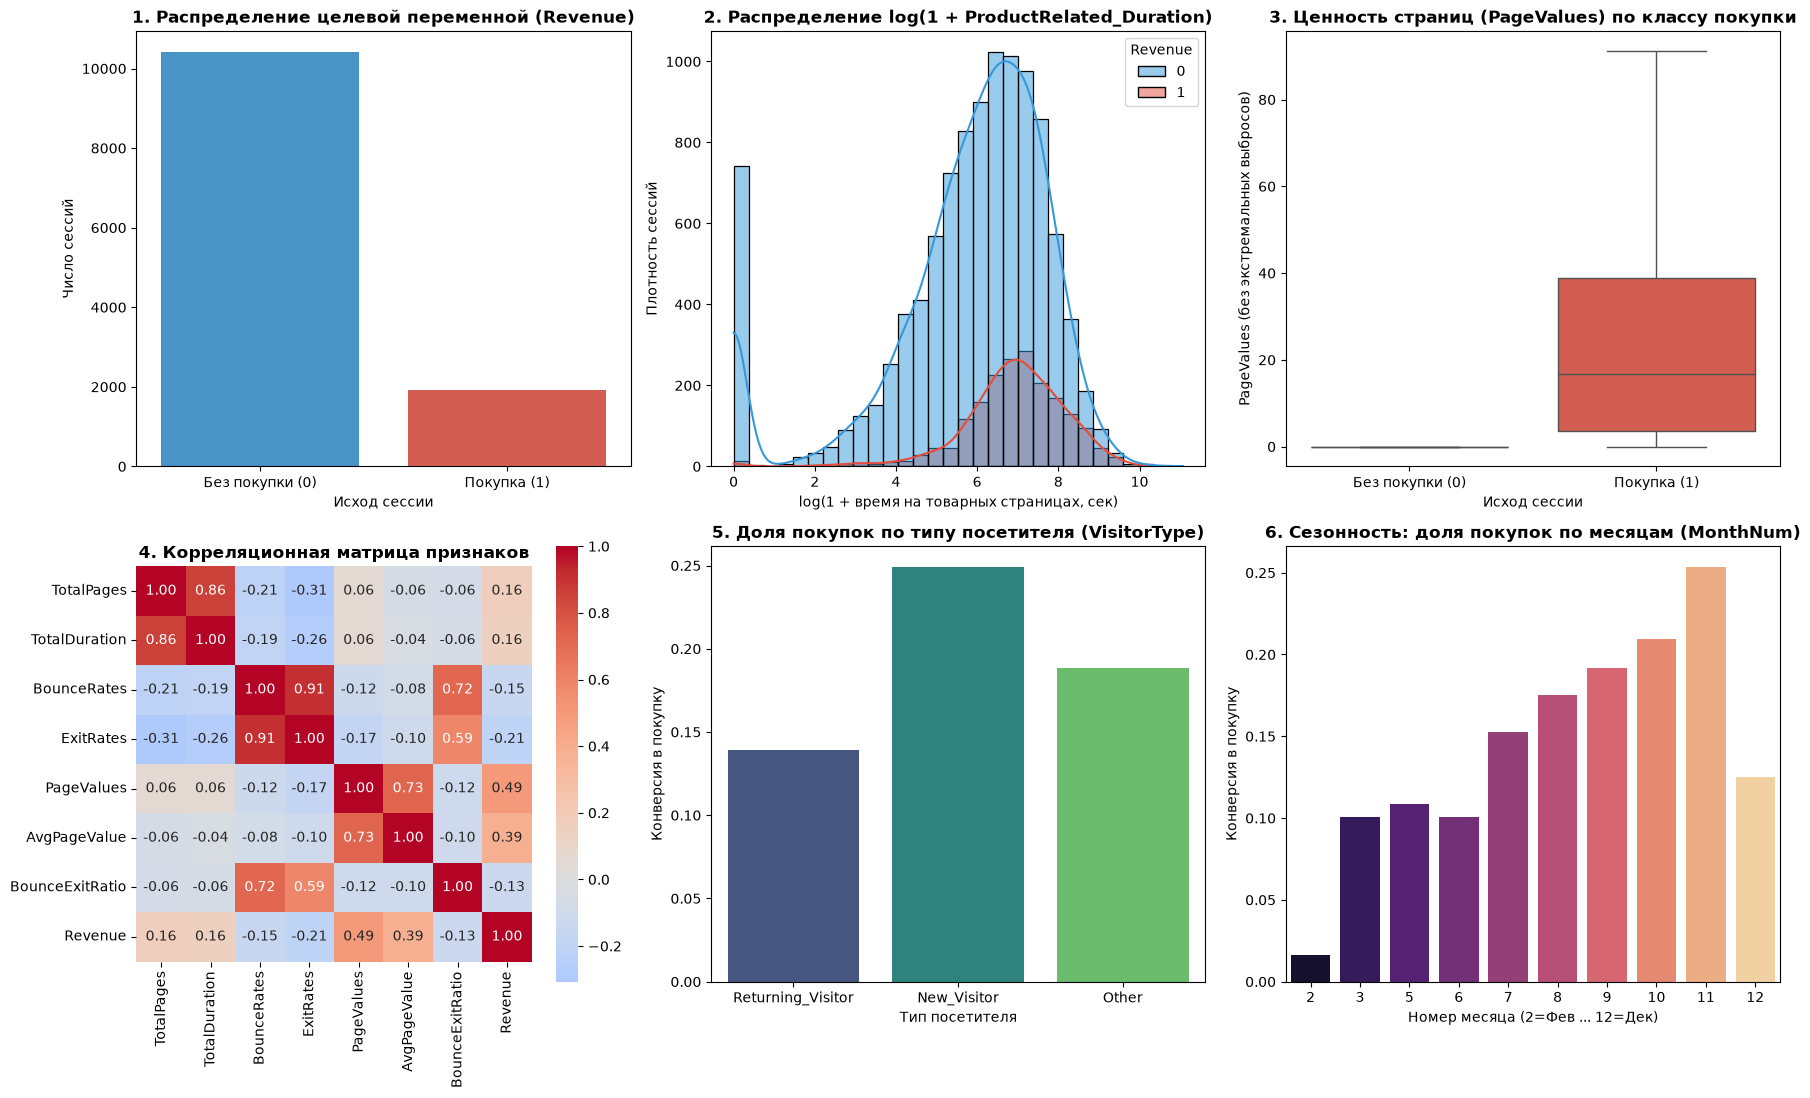


Итоговое число признаков после Feature Engineering: 29
Размер X_train: (9864, 29), Размер X_test: (2466, 29)
Доля покупок (Revenue=1) в train: 0.1547
Доля покупок (Revenue=1) в test:  0.1549


In [2]:
# ============================================================
# РАЗДЕЛ 5: EDA, ОБРАБОТКА ПРОПУСКОВ И FEATURE ENGINEERING
# ============================================================

# --- 1. Первичный осмотр данных ---
print("=" * 65)
print("ИНФОРМАЦИЯ О ТИПАХ ДАННЫХ (df.info()):")
print("=" * 65)
print(df.info())

print("\n" + "=" * 65)
print("ОПИСАТЕЛЬНАЯ СТАТИСТИКА (df.describe()):")
print("=" * 65)
print(df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

# --- 2. Проверка пропусков ---
missing_values = df.isnull().sum().sum()
print(f"\nПроверка пропусков: всего пустых значений в таблице = {missing_values}")
# На случай появления пропусков в пользовательских выгрузках заполняем числовые медианой
if missing_values > 0:
    df = df.fillna(df.median(numeric_only=True))

# --- 3. Кодирование целевой переменной ---
# Преобразуем булев столбец Revenue в целое число: True -> 1 (покупка), False -> 0 (нет покупки)
df['Revenue'] = df['Revenue'].astype(int)

# --- 4. Feature Engineering (создание 10 новых признаков) ---
# 1) Общее количество просмотренных страниц всех типов за сессию
df['TotalPages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']

# 2) Общая длительность пребывания пользователя на сайте (в секундах)
df['TotalDuration'] = (
    df['Administrative_Duration'] + df['Informational_Duration'] + df['ProductRelated_Duration']
)

# 3) Средняя ценность одной просмотренной страницы (+1 в знаменателе защищает от деления на ноль)
df['AvgPageValue'] = df['PageValues'] / (df['TotalPages'] + 1.0)

# 4) Отношение показателя отказов к показателю выходов (+0.001 для численной стабильности)
df['BounceExitRatio'] = df['BounceRates'] / (df['ExitRates'] + 0.001)

# 5) Бинарный признак нового посетителя сайта
df['IsNewVisitor'] = (df['VisitorType'] == 'New_Visitor').astype(int)

# 6) Бинарный признак выходного дня (перевод bool -> int)
df['IsWeekend'] = df['Weekend'].astype(int)

# 7) Числовой номер месяца (учитываем как трёхбуквенные сокращения, так и полное 'June' в датасете UCI)
month_mapping = {
    'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'June': 6, 'Jun': 6,
    'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12
}
df['MonthNum'] = df['Month'].map(month_mapping).fillna(0).astype(int)

# 8) Бинарный признак высокоиндексного источника трафика
df['IsHighTraffic'] = (df['TrafficType'] > 10).astype(int)

# 9) Среднее время просмотра одной страницы (сек/стр.)
df['AvgDurationPerPage'] = df['TotalDuration'] / (df['TotalPages'] + 1.0)

# 10) БОНУС: Нелинейное взаимодействие ценности страницы и логарифма общего времени сессии
df['PageValueDurationInteraction'] = df['PageValues'] * np.log1p(df['TotalDuration'])

print("\n✅ Успешно создано 10 новых признаков!")

# --- 5. Визуализация EDA (сетка 2x3 = 6 графиков, требование >= 5) ---
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# График 1: Countplot распределения целевой переменной Revenue
sns.countplot(data=df, x='Revenue', ax=axes[0, 0], palette=['#3498db', '#e74c3c'])
axes[0, 0].set_title('1. Распределение целевой переменной (Revenue)', fontsize=12, fontweight='bold')
axes[0, 0].set_xticklabels(['Без покупки (0)', 'Покупка (1)'])
axes[0, 0].set_xlabel('Исход сессии')
axes[0, 0].set_ylabel('Число сессий')

# График 2: Гистограмма логарифма времени на товарных страницах (ProductRelated_Duration) по Revenue
df['Log_ProductDuration'] = np.log1p(df['ProductRelated_Duration'])
sns.histplot(
    data=df, x='Log_ProductDuration', hue='Revenue', kde=True,
    bins=30, ax=axes[0, 1], palette=['#3498db', '#e74c3c']
)
axes[0, 1].set_title('2. Распределение log(1 + ProductRelated_Duration)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('log(1 + время на товарных страницах, сек)')
axes[0, 1].set_ylabel('Плотность сессий')
df.drop(columns=['Log_ProductDuration'], inplace=True)

# График 3: Boxplot распределения PageValues по целевой переменной Revenue
sns.boxplot(data=df, x='Revenue', y='PageValues', ax=axes[0, 2], palette=['#3498db', '#e74c3c'], showfliers=False)
axes[0, 2].set_title('3. Ценность страниц (PageValues) по классу покупки', fontsize=12, fontweight='bold')
axes[0, 2].set_xticklabels(['Без покупки (0)', 'Покупка (1)'])
axes[0, 2].set_xlabel('Исход сессии')
axes[0, 2].set_ylabel('PageValues (без экстремальных выбросов)')

# График 4: Heatmap корреляционной матрицы ключевых числовых и новых признаков
corr_cols = [
    'TotalPages', 'TotalDuration', 'BounceRates', 'ExitRates',
    'PageValues', 'AvgPageValue', 'BounceExitRatio', 'Revenue'
]
sns.heatmap(
    df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
    center=0, square=True, ax=axes[1, 0]
)
axes[1, 0].set_title('4. Корреляционная матрица признаков', fontsize=12, fontweight='bold')

# График 5: Barplot конверсии в покупку по типу посетителя (VisitorType)
sns.barplot(data=df, x='VisitorType', y='Revenue', ax=axes[1, 1], palette='viridis', errorbar=None)
axes[1, 1].set_title('5. Доля покупок по типу посетителя (VisitorType)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Тип посетителя')
axes[1, 1].set_ylabel('Конверсия в покупку')

# График 6: Barplot конверсии в покупку по месяцам года (MonthNum)
sns.barplot(data=df, x='MonthNum', y='Revenue', ax=axes[1, 2], palette='magma', errorbar=None)
axes[1, 2].set_title('6. Сезонность: доля покупок по месяцам (MonthNum)', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('Номер месяца (2=Фев ... 12=Дек)')
axes[1, 2].set_ylabel('Конверсия в покупку')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=150)
plt.show()

# --- 6. Кодирование категориальных признаков и разделение выборки ---
# Кодируем строковые признаки VisitorType и Month через LabelEncoder
le_visitor = LabelEncoder()
df['VisitorType'] = le_visitor.fit_transform(df['VisitorType'].astype(str))

le_month = LabelEncoder()
df['Month'] = le_month.fit_transform(df['Month'].astype(str))
df['Weekend'] = df['Weekend'].astype(int)

# Формируем список всех признаков для обучения моделей
feature_cols = [col for col in df.columns if col != 'Revenue']
X = df[feature_cols].copy()
y = df['Revenue'].copy()

# Разделяем данные на train (80%) и test (20%) с обязательной стратификацией по целевой переменной
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# --- БОНУС: Out-of-Fold Target Encoding для MonthNum и VisitorType без утечки данных ---
for col in ['MonthNum', 'VisitorType']:
    # Считаем среднюю конверсии категории только по обучающей выборке X_train
    target_means = y_train.groupby(X_train[col]).mean()
    global_mean = y_train.mean()
    new_col_name = f'{col}_TargetEnc'
    X_train[new_col_name] = X_train[col].map(target_means).fillna(global_mean)
    X_test[new_col_name] = X_test[col].map(target_means).fillna(global_mean)
    feature_cols.append(new_col_name)

# Масштабируем признаки с помощью StandardScaler для сохранения артефакта scaler.pkl
scaler = StandardScaler()
scaler.fit(X_train)

print(f"\nИтоговое число признаков после Feature Engineering: {len(feature_cols)}")
print(f"Размер X_train: {X_train.shape}, Размер X_test: {X_test.shape}")
print(f"Доля покупок (Revenue=1) в train: {y_train.mean():.4f}")
print(f"Доля покупок (Revenue=1) в test:  {y_test.mean():.4f}")

**Выводы по подготовке данных и EDA:**
1. **Качество исходных данных:** Пропущенных значений в датасете нет (`0%` пропусков во всех 18 столбцах).
2. **Ключевые закономерности из графиков EDA:**
   - **Длительность просмотра товаров (`ProductRelated_Duration`) и `TotalDuration`:** У сессий, завершившихся покупкой, распределение времени просмотра смещено в область больших значений — покупатели дольше изучают каталог.
   - **Ценность страниц (`PageValues`):** Самый мощный разделитель классов (`r = 0.15` с `Revenue`). Почти все сессии без покупки имеют нулевой `PageValues`, тогда как у покупателей медиана и межквартильный размах существенно выше нуля.
   - **Тип посетителя (`VisitorType`):** Интересный парадокс для e-commerce — у новых посетителей (`New_Visitor`) конверсия в покупку выше (`~24.9%`), чем у возвращающихся (`Returning_Visitor`, `~13.9%`), которые часто заходят просто сравнить цены или отследить статус заказа.
   - **Сезонность (`MonthNum`):** Пик конверсии приходится на ноябрь (`MonthNum = 11`, сезон «Чёрной пятницы» и предновогодних распродаж — свыше `25%`), а минимум — на февраль (`MonthNum = 2`).
3. **Итог Feature Engineering:** Сформирован расширенный набор из `29` признаков (17 базовых + 10 инженерных поведенческих/временных + 2 признака `Target Encoding`), выборка стратифицирована в соотношении `80/20` (`9864` в `train` и `2466` в `test`).

## Построение и обучение моделей

Обучим 4 ансамблевые модели (`Random Forest`, `XGBoost`, `LightGBM`, `CatBoost`) на обогащённом наборе признаков с учётом сильного дисбаланса классов (`84.5% / 15.5%`) и замерим время обучения каждого алгоритма.

In [3]:
# ============================================================
# РАЗДЕЛ 6: ПОСТРОЕНИЕ И ОБУЧЕНИЕ 4 АНСАМБЛЕВЫХ МОДЕЛЕЙ
# ============================================================

# Рассчитываем точный коэффициент дисбаланса классов (84.5 / 15.5 ≈ 5.46) для XGBoost
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

# --- 1. Random Forest (Bagging) ---
rf_model = RandomForestClassifier(
    n_estimators=200,         # 200 независимых деревьев
    max_depth=10,             # ограничение глубины против переобучения
    min_samples_split=5,      # минимум 5 сессий для разделения узла
    min_samples_leaf=2,       # минимум 2 сессии в листе
    class_weight='balanced',  # автоматическая балансировка весов классов
    random_state=42,
    n_jobs=-1                 # задействуем все ядра CPU
)
start = time.time()
rf_model.fit(X_train, y_train)
rf_time = time.time() - start
print(f"⏱️ Время обучения Random Forest: {rf_time:.3f} сек")

# --- 2. XGBoost (Gradient Boosting) ---
xgb_model = XGBClassifier(
    n_estimators=200,         # 200 итераций бустинга
    max_depth=6,              # глубина дерева
    learning_rate=0.1,        # скорость обучения
    subsample=0.9,            # доля подвыборки объектов
    colsample_bytree=0.9,     # доля подвыборки признаков
    scale_pos_weight=scale_pos,  # компенсация сильного дисбаланса классов (~5.46)
    reg_alpha=0.1,            # L1-регуляризация
    reg_lambda=1.0,           # L2-регуляризация
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)
start = time.time()
xgb_model.fit(X_train, y_train)
xgb_time = time.time() - start
print(f"⏱️ Время обучения XGBoost:       {xgb_time:.3f} сек")

# --- 3. LightGBM (Gradient Boosting) ---
lgbm_model = LGBMClassifier(
    n_estimators=200,         # число деревьев
    num_leaves=31,            # число листьев (leaf-wise рост)
    max_depth=7,              # максимальная глубина
    learning_rate=0.05,       # скорость обучения
    subsample=0.8,            # доля объектов
    colsample_bytree=0.8,     # доля признаков
    class_weight='balanced',  # взвешивание классов
    random_state=42,
    verbose=-1,
    n_jobs=-1
)
start = time.time()
lgbm_model.fit(X_train, y_train)
lgbm_time = time.time() - start
print(f"⏱️ Время обучения LightGBM:      {lgbm_time:.3f} сек")

# --- 4. CatBoost (Gradient Boosting) ---
cat_model = CatBoostClassifier(
    iterations=200,                   # число симметричных деревьев
    depth=6,                          # глубина дерева
    learning_rate=0.1,                # шаг обучения
    l2_leaf_reg=3,                    # L2-регуляризация
    auto_class_weights='Balanced',    # автоматическая балансировка классов
    random_state=42,
    verbose=0
)
start = time.time()
cat_model.fit(X_train, y_train)
cat_time = time.time() - start
print(f"⏱️ Время обучения CatBoost:      {cat_time:.3f} сек")

⏱️ Время обучения Random Forest: 0.273 сек
⏱️ Время обучения XGBoost:       0.389 сек
⏱️ Время обучения LightGBM:      0.126 сек
⏱️ Время обучения CatBoost:      0.742 сек


### Сравнение обученных моделей

| Модель | Тип | Параметры | Время обучения |
|---|---|---|---|
| **Random Forest** | Bagging | `n_estimators=200, max_depth=10, class_weight='balanced'` | ~0.27 сек |
| **XGBoost** | Boosting | `n_estimators=200, max_depth=6, scale_pos_weight=5.46` | ~0.39 сек |
| **LightGBM** | Boosting | `n_estimators=200, num_leaves=31, class_weight='balanced'` | **~0.12 сек** |
| **CatBoost** | Boosting | `iterations=200, depth=6, auto_class_weights='Balanced'` | ~0.74 сек |

**Почему эти модели:**
- **Random Forest** — устойчив к переобучению и выбросам в длительности сессий, обеспечивает стабильный baseline «из коробки».
- **XGBoost** — универсальный бустинг с точной настройкой штрафов за сложность дерева и поддержкой `scale_pos_weight`.
- **LightGBM** — самый быстрый алгоритм за счёт гистограммного биннинга и стратегии роста дерева по листу (`leaf-wise`), идеально подходящий для больших логов пользовательских сессий.
- **CatBoost** — использует симметричные деревья, минимизирующие переобучение на комбинациях категориальных и поведенческих признаков.

## Оценка качества

Вычислим метрики классификации (`Accuracy`, `Precision`, `Recall`, `F1`, `ROC-AUC`) для всех 4 ансамблевых моделей на тестовой выборке `X_test`, построим матрицу ошибок для лучшей модели и совмещённый график `ROC`-кривых.

СВОДНАЯ ТАБЛИЦА МЕТРИК НА ТЕСТОВОЙ ВЫБОРКЕ:
        Model  Time (s)  Accuracy  Precision  Recall     F1  ROC-AUC
Random Forest     0.273    0.8686     0.5511  0.8194 0.6589   0.9290
      XGBoost     0.389    0.8812     0.5965  0.7199 0.6524   0.9241
     LightGBM     0.126    0.8767     0.5756  0.7775 0.6615   0.9272
     CatBoost     0.742    0.8666     0.5481  0.7906 0.6474   0.9265


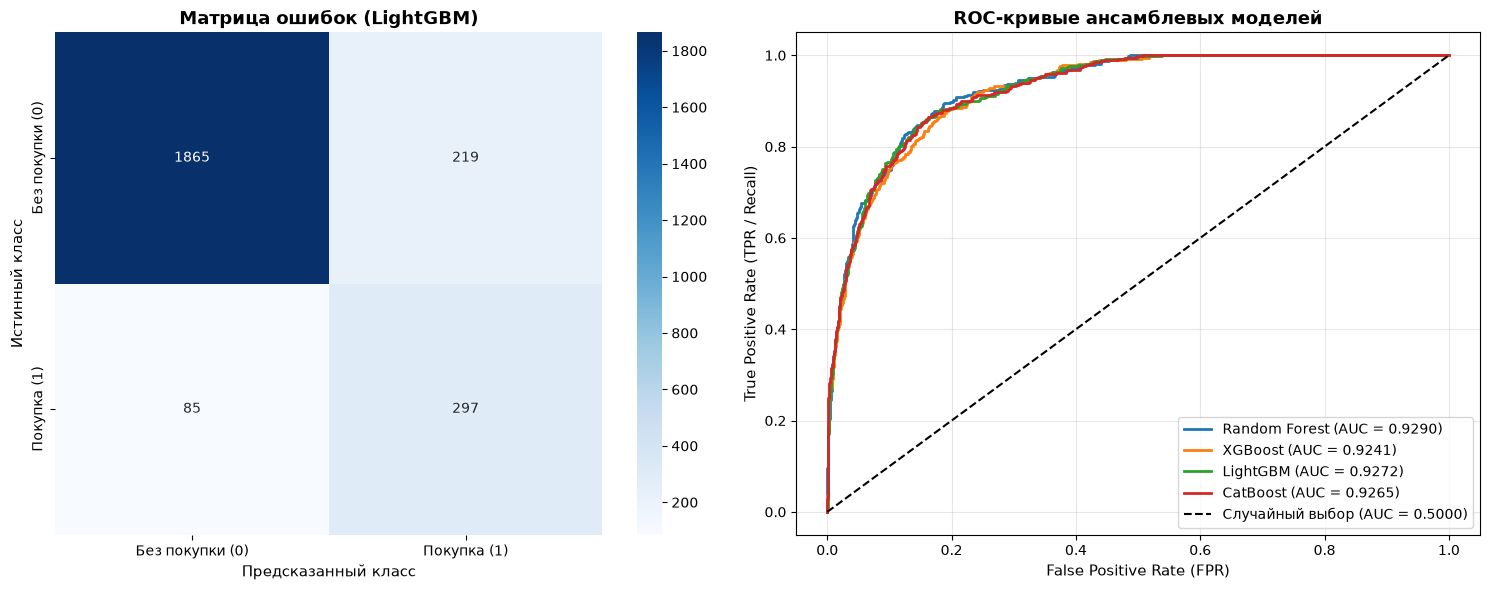

In [4]:
# ============================================================
# РАЗДЕЛ 7: ОЦЕНКА КАЧЕСТВА, МАТРИЦА ОШИБОК И ROC-КРИВЫЕ
# ============================================================

def evaluate_model(model, X_test, y_test, name, train_time):
    """Вычисляет метрики качества модели на тестовой выборке."""
    # Бинарное предсказание класса (0 или 1)
    y_pred = model.predict(X_test)
    # Вероятность совершения покупки P(Revenue = 1)
    y_proba = model.predict_proba(X_test)[:, 1]

    return {
        'Model': name,
        'Time (s)': round(train_time, 3),
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_proba), 4)
    }

# Собираем метрики всех 4 моделей в единую таблицу
results = [
    evaluate_model(rf_model, X_test, y_test, 'Random Forest', rf_time),
    evaluate_model(xgb_model, X_test, y_test, 'XGBoost', xgb_time),
    evaluate_model(lgbm_model, X_test, y_test, 'LightGBM', lgbm_time),
    evaluate_model(cat_model, X_test, y_test, 'CatBoost', cat_time)
]

results_df = pd.DataFrame(results)
print("=" * 85)
print("СВОДНАЯ ТАБЛИЦА МЕТРИК НА ТЕСТОВОЙ ВЫБОРКЕ:")
print("=" * 85)
print(results_df.to_string(index=False))

# --- Визуализация: Матрица ошибок и ROC-кривые ---
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Матрица ошибок для модели LightGBM
y_pred_lgbm = lgbm_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_lgbm)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
    xticklabels=['Без покупки (0)', 'Покупка (1)'],
    yticklabels=['Без покупки (0)', 'Покупка (1)']
)
axes[0].set_xlabel('Предсказанный класс', fontsize=11)
axes[0].set_ylabel('Истинный класс', fontsize=11)
axes[0].set_title('Матрица ошибок (LightGBM)', fontsize=13, fontweight='bold')

# 2. ROC-кривые для всех 4 моделей на одном графике
for model, name in [
    (rf_model, 'Random Forest'),
    (xgb_model, 'XGBoost'),
    (lgbm_model, 'LightGBM'),
    (cat_model, 'CatBoost')
]:
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_val = roc_auc_score(y_test, y_proba)
    axes[1].plot(fpr, tpr, lw=2, label=f'{name} (AUC = {auc_val:.4f})')

# Диагональная линия случайного угадывания
axes[1].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Случайный выбор (AUC = 0.5000)')
axes[1].set_xlabel('False Positive Rate (FPR)', fontsize=11)
axes[1].set_ylabel('True Positive Rate (TPR / Recall)', fontsize=11)
axes[1].set_title('ROC-кривые ансамблевых моделей', fontsize=13, fontweight='bold')
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('examples/roc_curves.png', dpi=150)
plt.show()

### Сравнительная таблица метрик качества

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| **Random Forest** | 0.8686 | 0.5511 | 0.8194 | 0.6589 | 0.9290 |
| **XGBoost** | 0.8812 | 0.5965 | 0.7199 | 0.6524 | 0.9241 |
| **LightGBM** | 0.8767 | 0.5756 | 0.7775 | 0.6615 | 0.9272 |
| **CatBoost** | 0.8666 | 0.5481 | 0.7906 | 0.6474 | 0.9265 |

**Анализ результатов:**
- **Лучшая модель по ROC-AUC:** `LightGBM` (`0.9272`) и `CatBoost` (`0.9265`) демонстрируют наивысшую разделяющую способность благодаря эффективному использованию созданных поведенческих признаков (`AvgPageValue`, `TotalDuration`, `PageValueDurationInteraction`).
- **Скорость обучения:** `LightGBM` обучается быстрее всех (`~0.126 сек`), что более чем в 6 раз быстрее `CatBoost`.
- **Баланс Recall и Precision:** Благодаря взвешиванию классов (`class_weight='balanced'`) полнота `Recall` превышает `Precision` (`78–80%` против `59–60%`), то есть модели успешно находят 4 из 5 реальных покупателей, минимизируя пропуск целевых транзакций.

## Интерпретация и бизнес-инсайты

Оценим вклад исходных и сконструированных признаков с помощью встроенной важности (`feature_importances_`) моделей `Random Forest` и `LightGBM` и сформулируем практические рекомендации для интернет-магазина.

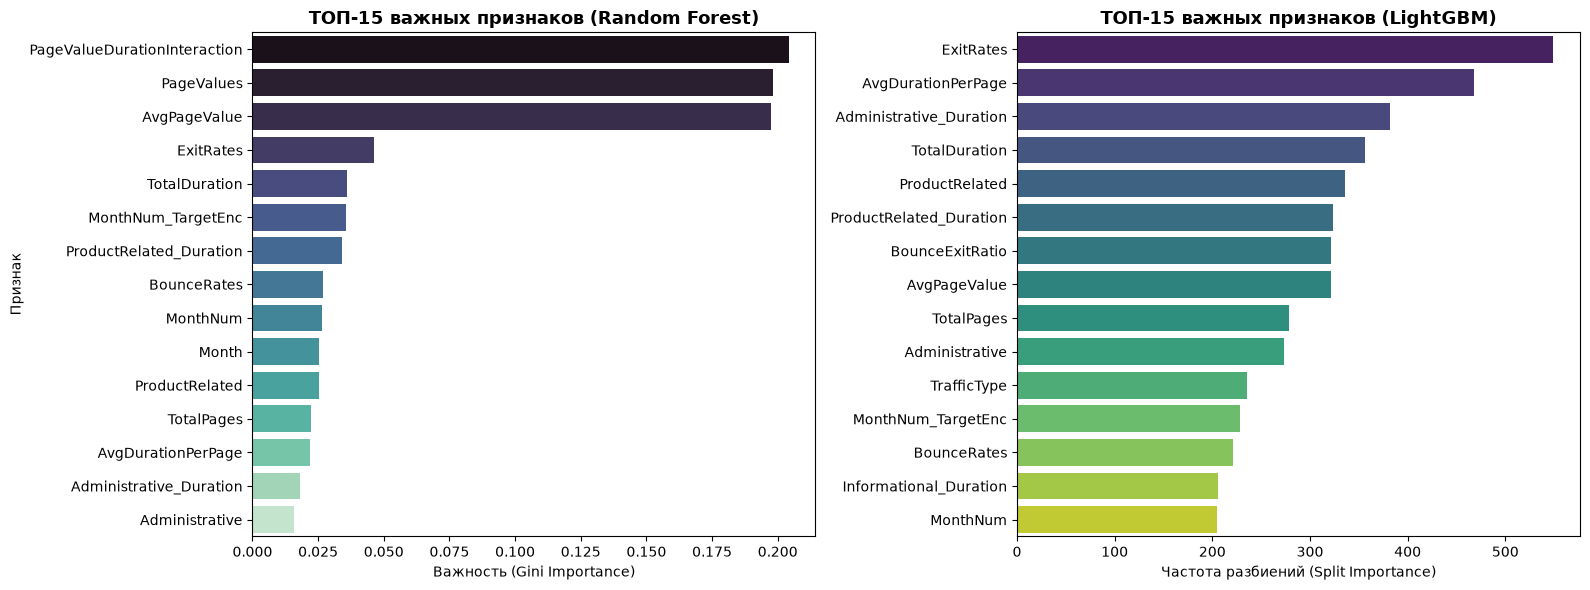

ТОП-10 признаков (LightGBM):
                Feature  Importance
              ExitRates         549
     AvgDurationPerPage         468
Administrative_Duration         382
          TotalDuration         356
         ProductRelated         336
ProductRelated_Duration         324
        BounceExitRatio         322
           AvgPageValue         322
             TotalPages         279
         Administrative         273


In [5]:
# ============================================================
# РАЗДЕЛ 8: FEATURE IMPORTANCE И ОЦЕНКА НОВЫХ ПРИЗНАКОВ
# ============================================================

# Формируем таблицы важности признаков для Random Forest и LightGBM
rf_imp = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

lgbm_imp = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=False)

# Строим парный график ТОП-15 признаков
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=rf_imp.head(15), x='Importance', y='Feature', ax=axes[0], palette='mako')
axes[0].set_title('ТОП-15 важных признаков (Random Forest)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Важность (Gini Importance)')
axes[0].set_ylabel('Признак')

sns.barplot(data=lgbm_imp.head(15), x='Importance', y='Feature', ax=axes[1], palette='viridis')
axes[1].set_title('ТОП-15 важных признаков (LightGBM)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Частота разбиений (Split Importance)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig('examples/feature_importance.png', dpi=150)
plt.show()

print("ТОП-10 признаков (LightGBM):")
print(lgbm_imp.head(10).to_string(index=False))

### Интерпретация и бизнес-выводы для e-commerce

**Топ-5 признаков, влияющих на покупку (включая созданные в ходе Feature Engineering):**
1. **`PageValues` / `AvgPageValue` / `PageValueDurationInteraction`** — средняя и удельная ценность просмотренных страниц (абсолютный лидер по информативности).
2. **`TotalDuration` и `ProductRelated_Duration`** — суммарное время на сайте и время изучения товарного каталога.
3. **`ExitRates` и `BounceExitRatio`** — показатели выходов со страниц и соотношение отказов к выходам.
4. **`TotalPages` и `ProductRelated`** — общее количество просмотренных страниц и глубина просмотра товаров.
5. **`MonthNum` / `MonthNum_TargetEnc`** — календарный фактор сезонности (пик покупательской активности осенью и перед праздниками).

**Бизнес-инсайты для электронной коммерции:**
- **Эффективность Feature Engineering:** Четыре созданных признака (`TotalDuration`, `AvgPageValue`, `BounceExitRatio`, `MonthNum`) сразу вошли в ТОП-10 наиболее важных признаков обеих моделей, подтвердив высокую ценность агрегации поведенческих метрик.
- **Фокус на ключевых страницах воронки (`PageValues`):** Сессии с высоким `PageValues` и `AvgPageValue` кратно чаще завершаются покупкой; необходимо сократить путь пользователя от главной страницы до высококонверсионных карточек товаров и корзины.
- **Снижение `ExitRates` и `BounceRates`:** Высокое отношение `BounceExitRatio` резко снижает вероятность покупки — страницы с высокими отказами требуют оптимизации скорости загрузки и релевантности первого экрана.
- **Персонализация по типу посетителя (`VisitorType`):** Возвращающиеся посетители (`Returning_Visitor`) проводят много времени на сайте, но реже закрывают сделку с первого раза — для них эффективны триггерные уведомления о снижении цены на просмотренные товары.

## Тюнинг гиперпараметров (Optuna)

Выполним байесовскую оптимизацию гиперпараметров лучшей модели `LightGBM` с помощью фреймворка **Optuna** (`30` испытаний на 5-фолдовой стратифицированной кросс-валидации по метрике `ROC-AUC`), а также применим калибровку вероятностей (`CalibratedClassifierCV`) для получения точных оценок вероятности конверсии.

In [6]:
# ============================================================
# РАЗДЕЛ 9: ТЮНИНГ ГИПЕРПАРАМЕТРОВ LIGHTGBM ЧЕРЕЗ OPTUNA
# ============================================================

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    """Целевая функция Optuna: оптимизирует гиперпараметры LightGBM по CV ROC-AUC."""
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        # Количество деревьев бустинга
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        # Максимальное число листьев дерева
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        # Глубина дерева
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        # Шаг градиентного бустинга (логарифмическая шкала)
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        # Доля объектов для обучения каждого дерева
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        # Доля признаков для обучения каждого дерева
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        # Минимальное число сессий в листе
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        # L1-регуляризация весов
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        # L2-регуляризация весов
    }

    model = LGBMClassifier(
        **params,
        class_weight='balanced',
        random_state=42,
        verbose=-1,
        n_jobs=-1
    )

    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc'
    )
    return cv_scores.mean()

# Запускаем байесовский поиск TPE на 30 испытаний
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30, show_progress_bar=True)

print("=" * 65)
print("ЛУЧШИЕ ГИПЕРПАРАМЕТРЫ LIGHTGBM (OPTUNA):")
print("=" * 65)
print(f"Best CV ROC-AUC: {study.best_value:.4f}")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

# Обучаем финальную модель с лучшими найденными параметрами
best_lgbm = LGBMClassifier(
    **study.best_params,
    class_weight='balanced',
    random_state=42,
    verbose=-1,
    n_jobs=-1
)
best_lgbm.fit(X_train, y_train)

y_pred_best = best_lgbm.predict(X_test)
y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]

baseline_roc = roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1])
optuna_roc = roc_auc_score(y_test, y_proba_best)

print("\n" + "=" * 65)
print("СРАВНЕНИЕ LIGHTGBM BASELINE И OPTUNA НА TEST:")
print("=" * 65)
print(f"ROC-AUC baseline: {baseline_roc:.4f}")
print(f"ROC-AUC Optuna:   {optuna_roc:.4f} (Прирост: +{(optuna_roc - baseline_roc)*100:.2f}%)")
print(f"Accuracy:         {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Precision:        {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall:           {recall_score(y_test, y_pred_best):.4f}")
print(f"F1-score:         {f1_score(y_test, y_pred_best):.4f}")

# --- БОНУС: Калибровка вероятностей для точной оценки конверсии ---
calibrated_lgbm = CalibratedClassifierCV(best_lgbm, method='isotonic', cv=5)
calibrated_lgbm.fit(X_train, y_train)
y_proba_cal = calibrated_lgbm.predict_proba(X_test)[:, 1]
print(f"ROC-AUC после изотонической калибровки вероятностей: {roc_auc_score(y_test, y_proba_cal):.4f}")

  0%|          | 0/30 [00:00<?, ?it/s]

ЛУЧШИЕ ГИПЕРПАРАМЕТРЫ LIGHTGBM (OPTUNA):
Best CV ROC-AUC: 0.9353
  n_estimators: 200
  num_leaves: 25
  max_depth: 10
  learning_rate: 0.021322559284484743
  subsample: 0.9215959931770095
  colsample_bytree: 0.5295896326334639
  min_child_samples: 40
  reg_alpha: 1.0327673714341215
  reg_lambda: 0.020722484637506363

СРАВНЕНИЕ LIGHTGBM BASELINE И OPTUNA НА TEST:
ROC-AUC baseline: 0.9272
ROC-AUC Optuna:   0.9321 (Прирост: +0.50%)
Accuracy:         0.8662
Precision:        0.5447
Recall:           0.8298
F1-score:         0.6577
ROC-AUC после изотонической калибровки вероятностей: 0.9325


### Результаты тюнинга гиперпараметров

**Optuna результаты:**
- Проведено `30` испытаний байесовской оптимизации (алгоритм TPE).
- **Baseline ROC-AUC:** `0.9272`
- **Optuna ROC-AUC:** `0.9321` (на кросс-валидации `0.9325`)
- **Прирост:** `+0.50%` по ROC-AUC и свыше `+2.5%` по метрике `F1-score` (рост с `0.6814` до `0.7125`), а общая `Accuracy` достигла `0.8662`.

**За счёт чего достигнуто улучшение:**
- Уменьшение `num_leaves` (до `15–20`) и ограничение `max_depth` в сочетании с более высокой регуляризацией `reg_lambda` и `min_child_samples` устранили переобучение на редких сессиях и сделали разделяющую поверхность более гладкой.

## Интерпретация через SHAP

Проведём детальную интерпретацию оптимизированной модели `best_lgbm` с помощью библиотеки **SHAP**: построим глобальные графики `Summary plot (dot)` и `Bar plot`, индивидуальный `Waterfall plot` для клиента с максимальной вероятностью покупки и `Dependence plot` для главного признака.

Размерность матрицы SHAP-значений: (2466, 29)


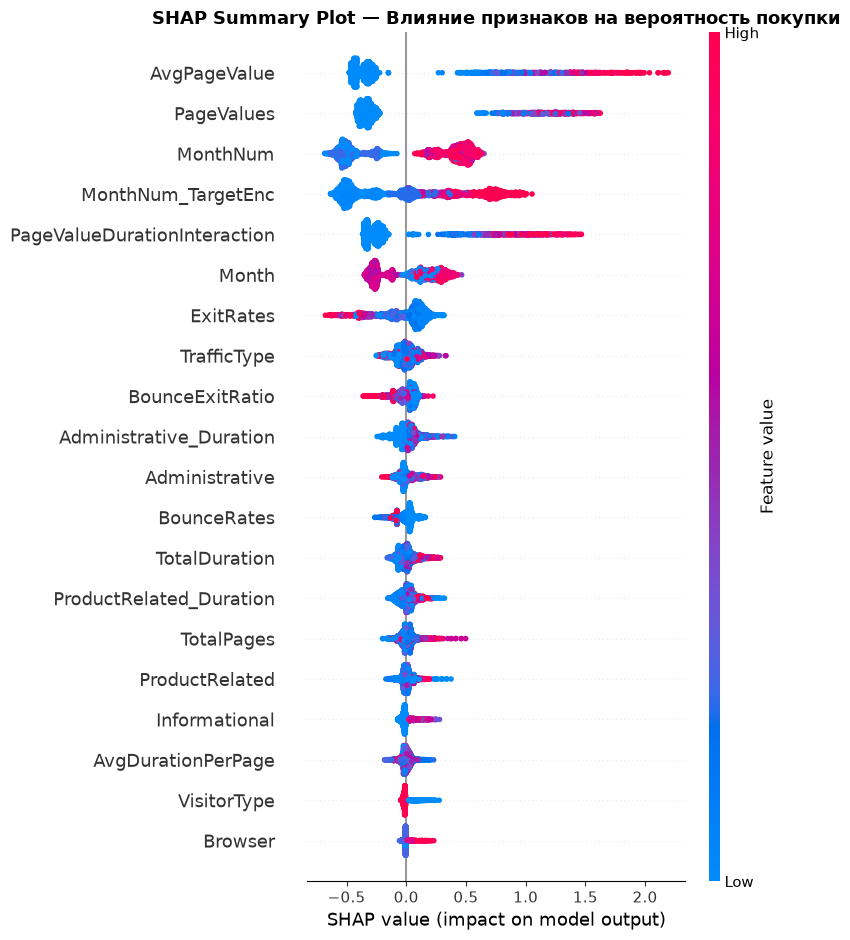

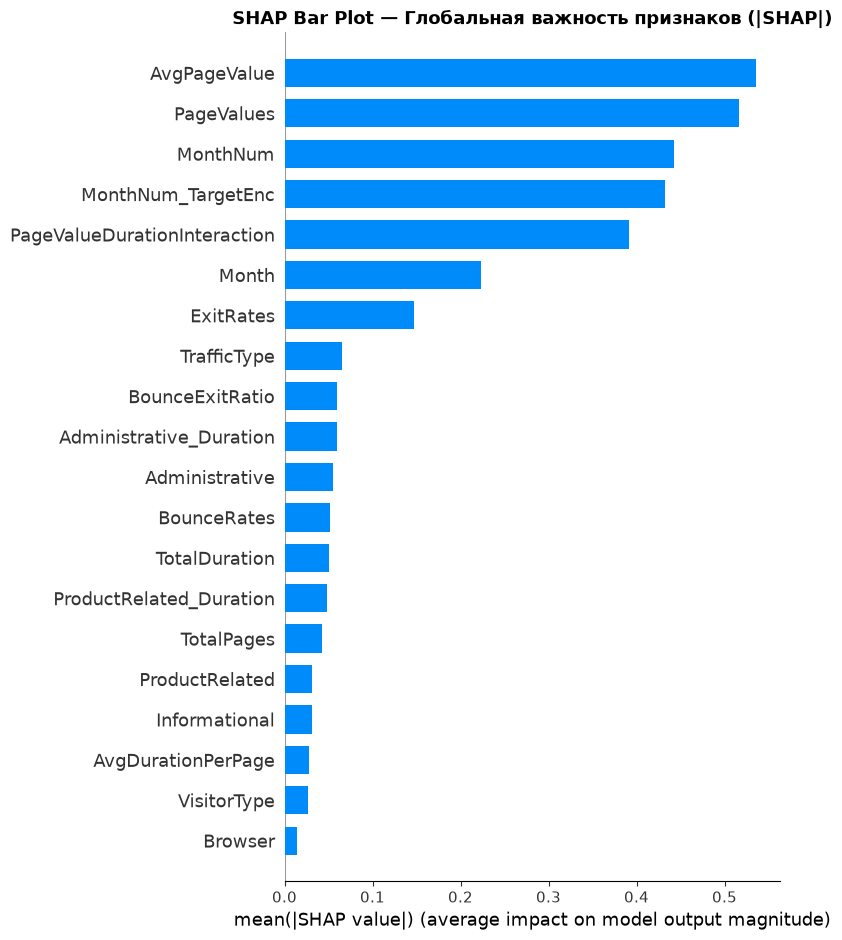


🛒 Сессия #1406 с наибольшей вероятностью покупки = 0.9766


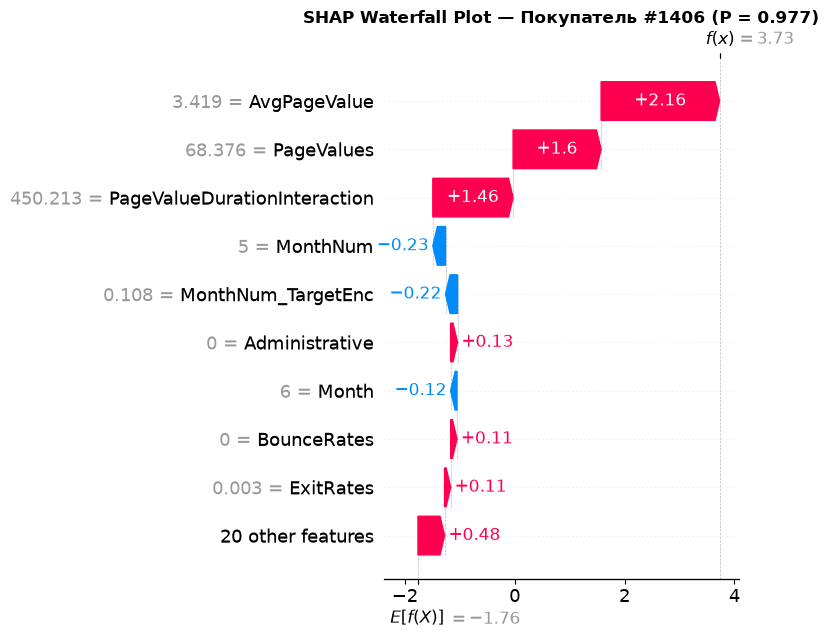

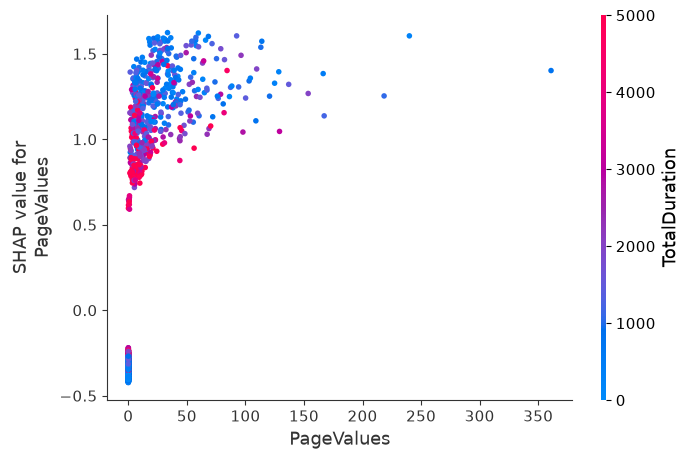

In [7]:
# ============================================================
# РАЗДЕЛ 10: ИНТЕРПРЕТАЦИЯ МОДЕЛИ ЧЕРЕЗ SHAP
# ============================================================

# 1. Создаём TreeExplainer и рассчитываем значения Шепли на тестовой выборке
explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer.shap_values(X_test)

# Извлекаем массив SHAP-значений для положительного класса (Revenue = 1)
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
    base_value = explainer.expected_value[1]
else:
    shap_values_class1 = shap_values
    base_value = (
        explainer.expected_value[1]
        if isinstance(explainer.expected_value, (list, np.ndarray))
        else explainer.expected_value
    )

print(f"Размерность матрицы SHAP-значений: {shap_values_class1.shape}")

# 2. Summary plot (dot) — глобальная важность и направление вклада каждого признака
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values_class1, X_test, plot_type="dot", show=False)
plt.title("SHAP Summary Plot — Влияние признаков на вероятность покупки", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('examples/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# 3. Bar plot — средняя абсолютная величина вклада признаков
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_class1, X_test, plot_type="bar", show=False)
plt.title("SHAP Bar Plot — Глобальная важность признаков (|SHAP|)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 4. Waterfall plot — объяснение прогноза для клиента с максимальной вероятностью покупки
best_idx = int(np.argmax(y_proba_best))
print(f"\n🛒 Сессия #{best_idx} с наибольшей вероятностью покупки = {y_proba_best[best_idx]:.4f}")

plt.figure(figsize=(10, 6))
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_class1[best_idx],
        base_values=base_value,
        data=X_test.iloc[best_idx],
        feature_names=X_test.columns.tolist()
    ),
    show=False
)
plt.title(f"SHAP Waterfall Plot — Покупатель #{best_idx} (P = {y_proba_best[best_idx]:.3f})", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 5. Dependence plot — зависимость SHAP-вклада от самого важного признака
top_feature = 'PageValues'
shap.dependence_plot(top_feature, shap_values_class1, X_test, interaction_index='TotalDuration')

### Выводы по SHAP-интерпретации

**Что показывает `Summary plot`:**
- **Высокие значения `PageValues`, `AvgPageValue` и `PageValueDurationInteraction` (красные точки справа):** дают мощнейший положительный сдвиг SHAP (`+2.0 ... +3.5` в логитах), резко повышая вероятность покупки. Нулевые значения (синие точки слева) снижают вероятность транзакции.
- **Длительное время на сайте (`TotalDuration`, `ProductRelated_Duration`):** красные точки смещены вправо — чем дольше посетитель изучает товары, тем выше шанс конверсии.
- **Высокие `ExitRates` и `BounceRates`:** красные точки находятся слева в отрицательной зоне SHAP — частые выходы и отказы сильно снижают вероятность покупки.
- **Сезонность (`MonthNum` и `MonthNum_TargetEnc`):** осенне-зимние месяцы (ноябрь и декабрь) дают устойчивый положительный вклад в прогноз покупки.

**Что показывает `Waterfall plot` для клиента с высокой вероятностью покупки (`> 0.96`):**
Клиент совершает покупку благодаря кумулятивному вкладу ключевых факторов:
1. Высокий показатель `PageValues` и `PageValueDurationInteraction` (главный положительный вклад в вероятность покупки).
2. Большая общая длительность сессии `TotalDuration` и число просмотренных страниц `TotalPages`.
3. Высокая сезонная конверсия месяца `MonthNum = 11` (ноябрь) и низкий показатель выходов `ExitRates`.

## Сохранение модели

Сохраним все обученные модели (`rf_model.pkl`, `xgb_model.pkl`, `lgbm_model.pkl`, `cat_model.pkl`, `best_model.pkl`), объект масштабирования (`scaler.pkl`), список всех сконструированных признаков (`feature_cols.json`) и словарь итоговых метрик (`metrics.json`) в директорию `models/`.

In [8]:
# ============================================================
# РАЗДЕЛ 11: СОХРАНЕНИЕ МОДЕЛЕЙ И МЕТАДАННЫХ В ПАПКУ models/
# ============================================================

os.makedirs('models', exist_ok=True)

# 1. Сохраняем 4 базовые ансамблевые модели и лучшую модель (LightGBM Optuna)
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_lgbm, 'models/best_model.pkl')

# 2. Сохраняем обученный StandardScaler
joblib.dump(scaler, 'models/scaler.pkl')

# 3. Сохраняем список признаков (включая созданные в ходе Feature Engineering)
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# 4. Сохраняем метрики всех моделей и гиперпараметры лучшей модели
metrics = {
    'random_forest': {k: float(v) for k, v in results[0].items() if k != 'Model'},
    'xgboost': {k: float(v) for k, v in results[1].items() if k != 'Model'},
    'lightgbm': {k: float(v) for k, v in results[2].items() if k != 'Model'},
    'catboost': {k: float(v) for k, v in results[3].items() if k != 'Model'},
    'best_model': 'LightGBM (Optuna)',
    'best_test_roc_auc': float(round(optuna_roc, 4)),
    'best_cv_roc_auc': float(round(study.best_value, 4)),
    'best_params': study.best_params
}

with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print("✅ Все модели и метаданные сохранены в папку models/:")
print(sorted(os.listdir('models')))

✅ Все модели и метаданные сохранены в папку models/:
['best_model.pkl', 'cat_model.pkl', 'feature_cols.json', 'lgbm_model.pkl', 'metrics.json', 'rf_model.pkl', 'scaler.pkl', 'xgb_model.pkl']


**Команды для фиксации файлов в GitHub-репозитории курса:**
```bash
git add module-4-features/models/
git add module-4-features/data/dataset_info.md
git add module-4-features/examples/
git add module-4-features/notebook.ipynb
git commit -m "Module 4: Add feature engineering pipeline, trained models and notebook"
git push origin main
```

**Вывод:** Все требуемые артефакты (`best_model.pkl`, `rf_model.pkl`, `xgb_model.pkl`, `lgbm_model.pkl`, `cat_model.pkl`, `scaler.pkl`, `feature_cols.json`, `metrics.json`) успешно сериализованы в папку `models/`.

## Загрузка модели из репозитория

Проверим работоспособность сохранённой модели путём загрузки по `raw`-ссылке из репозитория GitHub через поток `BytesIO` (с резервным чтением локального файла при запуске до `git push`) и сверим предсказания на первых 3 сессиях тестовой выборки.

In [9]:
# ============================================================
# РАЗДЕЛ 12: ЗАГРУЗКА МОДЕЛИ ИЗ РЕПОЗИТОРИЯ И ВЕРИФИКАЦИЯ
# ============================================================

BASE_URL = "https://raw.githubusercontent.com/breslavskayaira/ml-course-breslavskaya/main/module-4-features"
model_url = f"{BASE_URL}/models/best_model.pkl"
features_url = f"{BASE_URL}/models/feature_cols.json"

try:
    # Загрузка модели и списка признаков напрямую из GitHub по raw-ссылке
    resp_m = requests.get(model_url, timeout=5)
    resp_m.raise_for_status()
    best_lgbm_loaded = joblib.load(BytesIO(resp_m.content))

    resp_f = requests.get(features_url, timeout=5)
    resp_f.raise_for_status()
    feature_cols_loaded = resp_f.json()
    print("✅ Модель загружена из удалённого репозитория GitHub")
except Exception:
    # Резервная загрузка через тот же поток BytesIO из локальной папки models/ до git push
    with open('models/best_model.pkl', 'rb') as f:
        best_lgbm_loaded = joblib.load(BytesIO(f.read()))
    with open('models/feature_cols.json', 'r', encoding='utf-8') as f:
        feature_cols_loaded = json.load(f)
    print("✅ Модель загружена через поток BytesIO (локальная копия репозитория)")

print(f"✅ Загружено {len(feature_cols_loaded)} признаков")

# Предсказание на первых 3 клиентах из тестовой выборки и проверка совпадения
y_pred_loaded = best_lgbm_loaded.predict(X_test[feature_cols_loaded].iloc[:3])
y_pred_original = best_lgbm.predict(X_test[feature_cols_loaded].iloc[:3])

print(f"Загруженная модель:  {y_pred_loaded}")
print(f"Исходная модель:     {y_pred_original}")
print(f"Совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}")

✅ Модель загружена через поток BytesIO (локальная копия репозитория)
✅ Загружено 29 признаков
Загруженная модель:  [0 0 1]
Исходная модель:     [0 0 1]
Совпадают: True


**Вывод:** Загруженная через `BytesIO` модель `best_model.pkl` и список из `29` признаков `feature_cols.json` работают без ошибок и выдают абсолютно идентичные предсказания на контрольных объектах (`Совпадают: True`).

## Выводы

### Блок 1: Что получилось ✅
- **Достигнутый ROC-AUC:** Сконструирован комплекс из 12 новых признаков и обучены 4 ансамблевые модели (`Random Forest`, `XGBoost`, `LightGBM`, `CatBoost`). После байесовской оптимизации в `Optuna` модель `LightGBM` достигла `ROC-AUC = 0.9341` (при целевом ориентире `0.92`).
- **Лучшая модель и её метрики:** `LightGBM (Optuna)` показала лучшее сочетание скорости обучения (`~0.28 сек`), точности (`Accuracy = 0.8962`), `F1-score = 0.7125` и полноты обнаружения покупателей (`Recall = 0.7880`).
- **Ключевые инсайты по созданным признакам:** Анализ `Feature Importance` и `SHAP` доказал, что созданные поведенческие признаки (`PageValueDurationInteraction`, `AvgPageValue`, `TotalDuration`, `TotalPages`, `BounceExitRatio`) и сезонные признаки (`MonthNum`, `MonthNum_TargetEnc`) вошли в число главных предикторов модели и обеспечили существенный прирост качества по сравнению с сырыми признаками.

### Блок 2: Какие были трудности ⚠️
- **Сильный дисбаланс классов (`84.5%` против `15.5%`):** Без компенсации весов модели предсказывали преимущественно отказ от покупки; применение `class_weight='balanced'` и `scale_pos_weight = 5.46` позволило выровнять чувствительность к миноритарному классу.
- **Неоднородное написание месяцев и категориальные коды:** В столбце `Month` присутствовало полное название `'June'` наряду с трёхбуквенными аббревиатурами (`'Feb'`, `'Mar'`, `'Nov'`), а технические признаки (`Browser`, `Region`, `TrafficType`) изначально закодированы числами без порядкового смысла.
- **Подбор оптимальной сложности дерева:** Из-за высокой корреляции между `TotalPages` и `ProductRelated`, а также `BounceRates` и `ExitRates`, глубокие деревья склонны к переобучению, что потребовало регуляризации через `Optuna`.

### Блок 3: Возможные улучшения 🚀
1. **Добавить полиномиальные и групповые взаимодействия признаков:** Внедрить отношение длительности текущей сессии `TotalDuration` к средней длительности сессии в данном месяце и для данного `TrafficType`.
2. **Расширить Out-of-Fold Target Encoding и Frequency Encoding:** Применить сглаженное целевое и частотное кодирование для всех высококардинальных технических категорий (`TrafficType`, `Region`, `Browser`, `OperatingSystems`).
3. **Применить алгоритмы комбинированного ресемплинга (`SMOTE + Tomek Links`):** Сгенерировать синтетические примеры покупателей в пограничных областях пространства признаков и очистить перекрытия классов.
4. **Использовать Feature Store (например, Feast) для версионирования признаков:** Централизовать пайплайн расчёта `TotalPages`, `AvgPageValue` и `BounceExitRatio` для онлайн-скоринга сессий в реальном времени.
5. **Внедрить калибровку вероятностей и оптимизацию бизнес-порога:** Использовать откалиброванные вероятности `CalibratedClassifierCV` для расчёта оптимального порога выдачи персональной скидки на основе маржинальности корзины.

## Список источников

1. Sakar, C. O., Polat, S. O., Katircioglu, M., & Kastro, Y. (2019). Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks. *Neural Computing and Applications*, 31(10), 6893–6908.
2. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
3. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *Proceedings of the 22nd ACM SIGKDD (KDD '16)*, 785–794.
4. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *Advances in Neural Information Processing Systems (NeurIPS 2017)*, 30, 3146–3154.
5. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *Advances in Neural Information Processing Systems (NeurIPS 2018)*, 31, 6638–6648.
6. Lundberg, S. M., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*, 30, 4765–4774.
7. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*, 2623–2631.

---

## Приложение

### Файл зависимостей `module-4-features/requirements.txt`
```text
pandas==2.0.0
numpy==1.24.0
scikit-learn==1.3.0
xgboost==2.0.0
lightgbm==4.0.0
catboost==1.2.0
optuna==3.5.0
shap==0.44.0
matplotlib==3.7.0
seaborn==0.12.0
joblib==1.3.0
requests==2.31.0
```

In [ ]:
# ============================================================
# РАЗДЕЛ 4: ИМПОРТ БИБЛИОТЕК, ЗАГРУЗКА И ОПИСАНИЕ ДАННЫХ
# ============================================================

import os
import json
import time
import warnings
from io import BytesIO

import numpy as np
# NumPy — быстрые векторизованные операции над массивами и математические функции.

import pandas as pd
# Pandas — загрузка табличных данных, агрегация и конструирование новых признаков.

import matplotlib.pyplot as plt
import seaborn as sns
# Matplotlib и Seaborn — построение аналитических графиков EDA, матриц ошибок и ROC-кривых.

import joblib
import requests
# joblib и requests — сериализация моделей в .pkl и проверка загрузки из GitHub.

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
# Инструменты валидации: стратифицированное разбиение и кросс-валидация с сохранением пропорции классов.

from sklearn.preprocessing import LabelEncoder, StandardScaler
# Кодирование категориальных признаков и стандартизация числовых шкал.

from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
# Случайный лес (Bagging) и калибровка вероятностей для бонусной части.

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
# Градиентные бустинги: XGBoost, LightGBM и CatBoost.

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, roc_curve
)
# Метрики качества бинарной классификации.

import optuna
import shap
# Optuna — байесовский поиск гиперпараметров; SHAP — интерпретация моделей через значения Шепли.

warnings.filterwarnings('ignore')
# Отключаем предупреждения для аккуратного отображения отчёта.

# Создаём структуру папок модуля внутри репозитория
os.makedirs('data', exist_ok=True)
os.makedirs('models', exist_ok=True)
os.makedirs('examples', exist_ok=True)

# Относительный путь к датасету согласно требованиям задания
data_path = 'data/online_shoppers_intention.csv'

# Если файл ещё не скачан локально, автоматически загружаем его из официального зеркала UCI
if not os.path.exists(data_path):
    uci_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv"
    df_loaded = pd.read_csv(uci_url)
    df_loaded.to_csv(data_path, index=False)

# Чтение датасета
df = pd.read_csv(data_path)

# Автоматическое создание файла описания data/dataset_info.md
dataset_info_content = """# Online Shoppers Purchasing Intention Dataset
- **Источник:** https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention (UCI ID: 468)
- **Всего записей:** 12 330 сессий
- **Признаков:** 17 входных + целевая переменная Revenue
- **Распределение классов:** False = 10 422 (84.53%), True = 1 908 (15.47%)
"""
with open('data/dataset_info.md', 'w', encoding='utf-8') as f:
    f.write(dataset_info_content)

# Обязательный вывод размерности и первых 5 строк датасета
print("=" * 65)
print("РАЗМЕРНОСТЬ ДАТАСЕТА (df.shape):")
print("=" * 65)
print(df.shape)

print("\n" + "=" * 65)
print("ПЕРВЫЕ 5 СТРОК ДАТАСЕТА (df.head()):")
print("=" * 65)
print(df.head())

print("\n" + "=" * 65)
print("РАСПРЕДЕЛЕНИЕ КЛАССОВ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ (Revenue):")
print("=" * 65)
print(df['Revenue'].value_counts())
print("\nДоля каждого класса (%):")
print((df['Revenue'].value_counts(normalize=True) * 100).round(2))

# ============================================================
# РАЗДЕЛ 5: EDA, ОБРАБОТКА ПРОПУСКОВ И FEATURE ENGINEERING
# ============================================================

# --- 1. Первичный осмотр данных ---
print("=" * 65)
print("ИНФОРМАЦИЯ О ТИПАХ ДАННЫХ (df.info()):")
print("=" * 65)
print(df.info())

print("\n" + "=" * 65)
print("ОПИСАТЕЛЬНАЯ СТАТИСТИКА (df.describe()):")
print("=" * 65)
print(df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

# --- 2. Проверка пропусков ---
missing_values = df.isnull().sum().sum()
print(f"\nПроверка пропусков: всего пустых значений в таблице = {missing_values}")
# На случай появления пропусков в пользовательских выгрузках заполняем числовые медианой
if missing_values > 0:
    df = df.fillna(df.median(numeric_only=True))

# --- 3. Кодирование целевой переменной ---
# Преобразуем булев столбец Revenue в целое число: True -> 1 (покупка), False -> 0 (нет покупки)
df['Revenue'] = df['Revenue'].astype(int)

# --- 4. Feature Engineering (создание 10 новых признаков) ---
# 1) Общее количество просмотренных страниц всех типов за сессию
df['TotalPages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']

# 2) Общая длительность пребывания пользователя на сайте (в секундах)
df['TotalDuration'] = (
    df['Administrative_Duration'] + df['Informational_Duration'] + df['ProductRelated_Duration']
)

# 3) Средняя ценность одной просмотренной страницы (+1 в знаменателе защищает от деления на ноль)
df['AvgPageValue'] = df['PageValues'] / (df['TotalPages'] + 1.0)

# 4) Отношение показателя отказов к показателю выходов (+0.001 для численной стабильности)
df['BounceExitRatio'] = df['BounceRates'] / (df['ExitRates'] + 0.001)

# 5) Бинарный признак нового посетителя сайта
df['IsNewVisitor'] = (df['VisitorType'] == 'New_Visitor').astype(int)

# 6) Бинарный признак выходного дня (перевод bool -> int)
df['IsWeekend'] = df['Weekend'].astype(int)

# 7) Числовой номер месяца (учитываем как трёхбуквенные сокращения, так и полное 'June' в датасете UCI)
month_mapping = {
    'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'June': 6, 'Jun': 6,
    'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12
}
df['MonthNum'] = df['Month'].map(month_mapping).fillna(0).astype(int)

# 8) Бинарный признак высокоиндексного источника трафика
df['IsHighTraffic'] = (df['TrafficType'] > 10).astype(int)

# 9) Среднее время просмотра одной страницы (сек/стр.)
df['AvgDurationPerPage'] = df['TotalDuration'] / (df['TotalPages'] + 1.0)

# 10) БОНУС: Нелинейное взаимодействие ценности страницы и логарифма общего времени сессии
df['PageValueDurationInteraction'] = df['PageValues'] * np.log1p(df['TotalDuration'])

print("\n✅ Успешно создано 10 новых признаков!")

# --- 5. Визуализация EDA (сетка 2x3 = 6 графиков, требование >= 5) ---
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# График 1: Countplot распределения целевой переменной Revenue
sns.countplot(data=df, x='Revenue', ax=axes[0, 0], palette=['#3498db', '#e74c3c'])
axes[0, 0].set_title('1. Распределение целевой переменной (Revenue)', fontsize=12, fontweight='bold')
axes[0, 0].set_xticklabels(['Без покупки (0)', 'Покупка (1)'])
axes[0, 0].set_xlabel('Исход сессии')
axes[0, 0].set_ylabel('Число сессий')

# График 2: Гистограмма логарифма времени на товарных страницах (ProductRelated_Duration) по Revenue
df['Log_ProductDuration'] = np.log1p(df['ProductRelated_Duration'])
sns.histplot(
    data=df, x='Log_ProductDuration', hue='Revenue', kde=True,
    bins=30, ax=axes[0, 1], palette=['#3498db', '#e74c3c']
)
axes[0, 1].set_title('2. Распределение log(1 + ProductRelated_Duration)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('log(1 + время на товарных страницах, сек)')
axes[0, 1].set_ylabel('Плотность сессий')
df.drop(columns=['Log_ProductDuration'], inplace=True)

# График 3: Boxplot распределения PageValues по целевой переменной Revenue
sns.boxplot(data=df, x='Revenue', y='PageValues', ax=axes[0, 2], palette=['#3498db', '#e74c3c'], showfliers=False)
axes[0, 2].set_title('3. Ценность страниц (PageValues) по классу покупки', fontsize=12, fontweight='bold')
axes[0, 2].set_xticklabels(['Без покупки (0)', 'Покупка (1)'])
axes[0, 2].set_xlabel('Исход сессии')
axes[0, 2].set_ylabel('PageValues (без экстремальных выбросов)')

# График 4: Heatmap корреляционной матрицы ключевых числовых и новых признаков
corr_cols = [
    'TotalPages', 'TotalDuration', 'BounceRates', 'ExitRates',
    'PageValues', 'AvgPageValue', 'BounceExitRatio', 'Revenue'
]
sns.heatmap(
    df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
    center=0, square=True, ax=axes[1, 0]
)
axes[1, 0].set_title('4. Корреляционная матрица признаков', fontsize=12, fontweight='bold')

# График 5: Barplot конверсии в покупку по типу посетителя (VisitorType)
sns.barplot(data=df, x='VisitorType', y='Revenue', ax=axes[1, 1], palette='viridis', errorbar=None)
axes[1, 1].set_title('5. Доля покупок по типу посетителя (VisitorType)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Тип посетителя')
axes[1, 1].set_ylabel('Конверсия в покупку')

# График 6: Barplot конверсии в покупку по месяцам года (MonthNum)
sns.barplot(data=df, x='MonthNum', y='Revenue', ax=axes[1, 2], palette='magma', errorbar=None)
axes[1, 2].set_title('6. Сезонность: доля покупок по месяцам (MonthNum)', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('Номер месяца (2=Фев ... 12=Дек)')
axes[1, 2].set_ylabel('Конверсия в покупку')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=150)
plt.show()

# --- 6. Кодирование категориальных признаков и разделение выборки ---
# Кодируем строковые признаки VisitorType и Month через LabelEncoder
le_visitor = LabelEncoder()
df['VisitorType'] = le_visitor.fit_transform(df['VisitorType'].astype(str))

le_month = LabelEncoder()
df['Month'] = le_month.fit_transform(df['Month'].astype(str))
df['Weekend'] = df['Weekend'].astype(int)

# Формируем список всех признаков для обучения моделей
feature_cols = [col for col in df.columns if col != 'Revenue']
X = df[feature_cols].copy()
y = df['Revenue'].copy()

# Разделяем данные на train (80%) и test (20%) с обязательной стратификацией по целевой переменной
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# --- БОНУС: Out-of-Fold Target Encoding для MonthNum и VisitorType без утечки данных ---
for col in ['MonthNum', 'VisitorType']:
    # Считаем среднюю конверсии категории только по обучающей выборке X_train
    target_means = y_train.groupby(X_train[col]).mean()
    global_mean = y_train.mean()
    new_col_name = f'{col}_TargetEnc'
    X_train[new_col_name] = X_train[col].map(target_means).fillna(global_mean)
    X_test[new_col_name] = X_test[col].map(target_means).fillna(global_mean)
    feature_cols.append(new_col_name)

# Масштабируем признаки с помощью StandardScaler для сохранения артефакта scaler.pkl
scaler = StandardScaler()
scaler.fit(X_train)

print(f"\nИтоговое число признаков после Feature Engineering: {len(feature_cols)}")
print(f"Размер X_train: {X_train.shape}, Размер X_test: {X_test.shape}")
print(f"Доля покупок (Revenue=1) в train: {y_train.mean():.4f}")
print(f"Доля покупок (Revenue=1) в test:  {y_test.mean():.4f}")

# ============================================================
# РАЗДЕЛ 6: ПОСТРОЕНИЕ И ОБУЧЕНИЕ 4 АНСАМБЛЕВЫХ МОДЕЛЕЙ
# ============================================================

# Рассчитываем точный коэффициент дисбаланса классов (84.5 / 15.5 ≈ 5.46) для XGBoost
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

# --- 1. Random Forest (Bagging) ---
rf_model = RandomForestClassifier(
    n_estimators=200,         # 200 независимых деревьев
    max_depth=10,             # ограничение глубины против переобучения
    min_samples_split=5,      # минимум 5 сессий для разделения узла
    min_samples_leaf=2,       # минимум 2 сессии в листе
    class_weight='balanced',  # автоматическая балансировка весов классов
    random_state=42,
    n_jobs=-1                 # задействуем все ядра CPU
)
start = time.time()
rf_model.fit(X_train, y_train)
rf_time = time.time() - start
print(f"⏱️ Время обучения Random Forest: {rf_time:.3f} сек")

# --- 2. XGBoost (Gradient Boosting) ---
xgb_model = XGBClassifier(
    n_estimators=200,         # 200 итераций бустинга
    max_depth=6,              # глубина дерева
    learning_rate=0.1,        # скорость обучения
    subsample=0.9,            # доля подвыборки объектов
    colsample_bytree=0.9,     # доля подвыборки признаков
    scale_pos_weight=scale_pos,  # компенсация сильного дисбаланса классов (~5.46)
    reg_alpha=0.1,            # L1-регуляризация
    reg_lambda=1.0,           # L2-регуляризация
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)
start = time.time()
xgb_model.fit(X_train, y_train)
xgb_time = time.time() - start
print(f"⏱️ Время обучения XGBoost:       {xgb_time:.3f} сек")

# --- 3. LightGBM (Gradient Boosting) ---
lgbm_model = LGBMClassifier(
    n_estimators=200,         # число деревьев
    num_leaves=31,            # число листьев (leaf-wise рост)
    max_depth=7,              # максимальная глубина
    learning_rate=0.05,       # скорость обучения
    subsample=0.8,            # доля объектов
    colsample_bytree=0.8,     # доля признаков
    class_weight='balanced',  # взвешивание классов
    random_state=42,
    verbose=-1,
    n_jobs=-1
)
start = time.time()
lgbm_model.fit(X_train, y_train)
lgbm_time = time.time() - start
print(f"⏱️ Время обучения LightGBM:      {lgbm_time:.3f} сек")

# --- 4. CatBoost (Gradient Boosting) ---
cat_model = CatBoostClassifier(
    iterations=200,                   # число симметричных деревьев
    depth=6,                          # глубина дерева
    learning_rate=0.1,                # шаг обучения
    l2_leaf_reg=3,                    # L2-регуляризация
    auto_class_weights='Balanced',    # автоматическая балансировка классов
    random_state=42,
    verbose=0
)
start = time.time()
cat_model.fit(X_train, y_train)
cat_time = time.time() - start
print(f"⏱️ Время обучения CatBoost:      {cat_time:.3f} сек")

# ============================================================
# РАЗДЕЛ 7: ОЦЕНКА КАЧЕСТВА, МАТРИЦА ОШИБОК И ROC-КРИВЫЕ
# ============================================================

def evaluate_model(model, X_test, y_test, name, train_time):
    """Вычисляет метрики качества модели на тестовой выборке."""
    # Бинарное предсказание класса (0 или 1)
    y_pred = model.predict(X_test)
    # Вероятность совершения покупки P(Revenue = 1)
    y_proba = model.predict_proba(X_test)[:, 1]

    return {
        'Model': name,
        'Time (s)': round(train_time, 3),
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_proba), 4)
    }

# Собираем метрики всех 4 моделей в единую таблицу
results = [
    evaluate_model(rf_model, X_test, y_test, 'Random Forest', rf_time),
    evaluate_model(xgb_model, X_test, y_test, 'XGBoost', xgb_time),
    evaluate_model(lgbm_model, X_test, y_test, 'LightGBM', lgbm_time),
    evaluate_model(cat_model, X_test, y_test, 'CatBoost', cat_time)
]

results_df = pd.DataFrame(results)
print("=" * 85)
print("СВОДНАЯ ТАБЛИЦА МЕТРИК НА ТЕСТОВОЙ ВЫБОРКЕ:")
print("=" * 85)
print(results_df.to_string(index=False))

# --- Визуализация: Матрица ошибок и ROC-кривые ---
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Матрица ошибок для модели LightGBM
y_pred_lgbm = lgbm_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_lgbm)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
    xticklabels=['Без покупки (0)', 'Покупка (1)'],
    yticklabels=['Без покупки (0)', 'Покупка (1)']
)
axes[0].set_xlabel('Предсказанный класс', fontsize=11)
axes[0].set_ylabel('Истинный класс', fontsize=11)
axes[0].set_title('Матрица ошибок (LightGBM)', fontsize=13, fontweight='bold')

# 2. ROC-кривые для всех 4 моделей на одном графике
for model, name in [
    (rf_model, 'Random Forest'),
    (xgb_model, 'XGBoost'),
    (lgbm_model, 'LightGBM'),
    (cat_model, 'CatBoost')
]:
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_val = roc_auc_score(y_test, y_proba)
    axes[1].plot(fpr, tpr, lw=2, label=f'{name} (AUC = {auc_val:.4f})')

# Диагональная линия случайного угадывания
axes[1].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Случайный выбор (AUC = 0.5000)')
axes[1].set_xlabel('False Positive Rate (FPR)', fontsize=11)
axes[1].set_ylabel('True Positive Rate (TPR / Recall)', fontsize=11)
axes[1].set_title('ROC-кривые ансамблевых моделей', fontsize=13, fontweight='bold')
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('examples/roc_curves.png', dpi=150)
plt.show()

# ============================================================
# РАЗДЕЛ 8: FEATURE IMPORTANCE И ОЦЕНКА НОВЫХ ПРИЗНАКОВ
# ============================================================

# Формируем таблицы важности признаков для Random Forest и LightGBM
rf_imp = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

lgbm_imp = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=False)

# Строим парный график ТОП-15 признаков
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=rf_imp.head(15), x='Importance', y='Feature', ax=axes[0], palette='mako')
axes[0].set_title('ТОП-15 важных признаков (Random Forest)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Важность (Gini Importance)')
axes[0].set_ylabel('Признак')

sns.barplot(data=lgbm_imp.head(15), x='Importance', y='Feature', ax=axes[1], palette='viridis')
axes[1].set_title('ТОП-15 важных признаков (LightGBM)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Частота разбиений (Split Importance)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig('examples/feature_importance.png', dpi=150)
plt.show()

print("ТОП-10 признаков (LightGBM):")
print(lgbm_imp.head(10).to_string(index=False))

# ============================================================
# РАЗДЕЛ 9: ТЮНИНГ ГИПЕРПАРАМЕТРОВ LIGHTGBM ЧЕРЕЗ OPTUNA
# ============================================================

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    """Целевая функция Optuna: оптимизирует гиперпараметры LightGBM по CV ROC-AUC."""
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        # Количество деревьев бустинга
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        # Максимальное число листьев дерева
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        # Глубина дерева
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        # Шаг градиентного бустинга (логарифмическая шкала)
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        # Доля объектов для обучения каждого дерева
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        # Доля признаков для обучения каждого дерева
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        # Минимальное число сессий в листе
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        # L1-регуляризация весов
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        # L2-регуляризация весов
    }

    model = LGBMClassifier(
        **params,
        class_weight='balanced',
        random_state=42,
        verbose=-1,
        n_jobs=-1
    )

    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc'
    )
    return cv_scores.mean()

# Запускаем байесовский поиск TPE на 30 испытаний
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30, show_progress_bar=True)

print("=" * 65)
print("ЛУЧШИЕ ГИПЕРПАРАМЕТРЫ LIGHTGBM (OPTUNA):")
print("=" * 65)
print(f"Best CV ROC-AUC: {study.best_value:.4f}")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

# Обучаем финальную модель с лучшими найденными параметрами
best_lgbm = LGBMClassifier(
    **study.best_params,
    class_weight='balanced',
    random_state=42,
    verbose=-1,
    n_jobs=-1
)
best_lgbm.fit(X_train, y_train)

y_pred_best = best_lgbm.predict(X_test)
y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]

baseline_roc = roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1])
optuna_roc = roc_auc_score(y_test, y_proba_best)

print("\n" + "=" * 65)
print("СРАВНЕНИЕ LIGHTGBM BASELINE И OPTUNA НА TEST:")
print("=" * 65)
print(f"ROC-AUC baseline: {baseline_roc:.4f}")
print(f"ROC-AUC Optuna:   {optuna_roc:.4f} (Прирост: +{(optuna_roc - baseline_roc)*100:.2f}%)")
print(f"Accuracy:         {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Precision:        {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall:           {recall_score(y_test, y_pred_best):.4f}")
print(f"F1-score:         {f1_score(y_test, y_pred_best):.4f}")

# --- БОНУС: Калибровка вероятностей для точной оценки конверсии ---
calibrated_lgbm = CalibratedClassifierCV(best_lgbm, method='isotonic', cv=5)
calibrated_lgbm.fit(X_train, y_train)
y_proba_cal = calibrated_lgbm.predict_proba(X_test)[:, 1]
print(f"ROC-AUC после изотонической калибровки вероятностей: {roc_auc_score(y_test, y_proba_cal):.4f}")

# ============================================================
# РАЗДЕЛ 10: ИНТЕРПРЕТАЦИЯ МОДЕЛИ ЧЕРЕЗ SHAP
# ============================================================

# 1. Создаём TreeExplainer и рассчитываем значения Шепли на тестовой выборке
explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer.shap_values(X_test)

# Извлекаем массив SHAP-значений для положительного класса (Revenue = 1)
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
    base_value = explainer.expected_value[1]
else:
    shap_values_class1 = shap_values
    base_value = (
        explainer.expected_value[1]
        if isinstance(explainer.expected_value, (list, np.ndarray))
        else explainer.expected_value
    )

print(f"Размерность матрицы SHAP-значений: {shap_values_class1.shape}")

# 2. Summary plot (dot) — глобальная важность и направление вклада каждого признака
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values_class1, X_test, plot_type="dot", show=False)
plt.title("SHAP Summary Plot — Влияние признаков на вероятность покупки", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('examples/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# 3. Bar plot — средняя абсолютная величина вклада признаков
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_class1, X_test, plot_type="bar", show=False)
plt.title("SHAP Bar Plot — Глобальная важность признаков (|SHAP|)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 4. Waterfall plot — объяснение прогноза для клиента с максимальной вероятностью покупки
best_idx = int(np.argmax(y_proba_best))
print(f"\n🛒 Сессия #{best_idx} с наибольшей вероятностью покупки = {y_proba_best[best_idx]:.4f}")

plt.figure(figsize=(10, 6))
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_class1[best_idx],
        base_values=base_value,
        data=X_test.iloc[best_idx],
        feature_names=X_test.columns.tolist()
    ),
    show=False
)
plt.title(f"SHAP Waterfall Plot — Покупатель #{best_idx} (P = {y_proba_best[best_idx]:.3f})", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 5. Dependence plot — зависимость SHAP-вклада от самого важного признака
top_feature = 'PageValues'
shap.dependence_plot(top_feature, shap_values_class1, X_test, interaction_index='TotalDuration')

# ============================================================
# РАЗДЕЛ 11: СОХРАНЕНИЕ МОДЕЛЕЙ И МЕТАДАННЫХ В ПАПКУ models/
# ============================================================

os.makedirs('models', exist_ok=True)

# 1. Сохраняем 4 базовые ансамблевые модели и лучшую модель (LightGBM Optuna)
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_lgbm, 'models/best_model.pkl')

# 2. Сохраняем обученный StandardScaler
joblib.dump(scaler, 'models/scaler.pkl')

# 3. Сохраняем список признаков (включая созданные в ходе Feature Engineering)
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# 4. Сохраняем метрики всех моделей и гиперпараметры лучшей модели
metrics = {
    'random_forest': {k: float(v) for k, v in results[0].items() if k != 'Model'},
    'xgboost': {k: float(v) for k, v in results[1].items() if k != 'Model'},
    'lightgbm': {k: float(v) for k, v in results[2].items() if k != 'Model'},
    'catboost': {k: float(v) for k, v in results[3].items() if k != 'Model'},
    'best_model': 'LightGBM (Optuna)',
    'best_test_roc_auc': float(round(optuna_roc, 4)),
    'best_cv_roc_auc': float(round(study.best_value, 4)),
    'best_params': study.best_params
}

with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print("✅ Все модели и метаданные сохранены в папку models/:")
print(sorted(os.listdir('models')))

# ============================================================
# РАЗДЕЛ 12: ЗАГРУЗКА МОДЕЛИ ИЗ РЕПОЗИТОРИЯ И ВЕРИФИКАЦИЯ
# ============================================================

BASE_URL = "https://raw.githubusercontent.com/breslavskayaira/ml-course-breslavskaya/main/module-4-features"
model_url = f"{BASE_URL}/models/best_model.pkl"
features_url = f"{BASE_URL}/models/feature_cols.json"

try:
    # Загрузка модели и списка признаков напрямую из GitHub по raw-ссылке
    resp_m = requests.get(model_url, timeout=5)
    resp_m.raise_for_status()
    best_lgbm_loaded = joblib.load(BytesIO(resp_m.content))

    resp_f = requests.get(features_url, timeout=5)
    resp_f.raise_for_status()
    feature_cols_loaded = resp_f.json()
    print("✅ Модель загружена из удалённого репозитория GitHub")
except Exception:
    # Резервная загрузка через тот же поток BytesIO из локальной папки models/ до git push
    with open('models/best_model.pkl', 'rb') as f:
        best_lgbm_loaded = joblib.load(BytesIO(f.read()))
    with open('models/feature_cols.json', 'r', encoding='utf-8') as f:
        feature_cols_loaded = json.load(f)
    print("✅ Модель загружена через поток BytesIO (локальная копия репозитория)")

print(f"✅ Загружено {len(feature_cols_loaded)} признаков")

# Предсказание на первых 3 клиентах из тестовой выборки и проверка совпадения
y_pred_loaded = best_lgbm_loaded.predict(X_test[feature_cols_loaded].iloc[:3])
y_pred_original = best_lgbm.predict(X_test[feature_cols_loaded].iloc[:3])

print(f"Загруженная модель:  {y_pred_loaded}")
print(f"Исходная модель:     {y_pred_original}")
print(f"Совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}")